In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Tue Jun  7 12:02:15 2022

@author: sunms498
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
import pickle
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame

import numpy as np

import matplotlib.pyplot as plt
import xarray as xr

from matplotlib.colors import LogNorm
import cmcrameri.cm as cmc
import cmocean as cmo
################################################################################
#"""
"""
#filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_TOC_noconstraint_supervised_men_CS_.npy"
filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_dist_CS.npy"
prediction_dist_CS = np.load(filename)
prediction_dist_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_dist_DO.npy")


#np.save( "/gxfs_work/cau/sunms498/work_old/work/toc-neural-nets/SelectFeaturesRun/predictionmap_constraints/prediction_map_DO_noconstraint_supervised.npy", prediction_map)

uncertainty_map_CS = np.var(prediction_dist_CS, axis = 0)
prediction_map_CS = np.mean(prediction_dist_CS, axis = 0)

uncertainty_map_DO = np.var(prediction_dist_DO, axis = 0)
prediction_map_DO = np.mean(prediction_dist_DO, axis = 0)

uncertainty_map_CS = np.rot90(np.rot90(np.fliplr(uncertainty_map_CS)))
prediction_map_CS = np.rot90(np.rot90(np.fliplr(prediction_map_CS)))


uncertainty_map_DO = np.rot90(np.rot90(np.fliplr(uncertainty_map_DO)))
prediction_map_DO = np.rot90(np.rot90(np.fliplr(prediction_map_DO)))
"""
filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_TOC_supervised_men_CS_noconstraint.npy"
prediction_map_CS = np.load(filename)
prediction_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_TOC_noconstraint_supervised_men_DO.npy")

filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_supervised_men_CS_noconstraint.npy"
uncertainty_map_CS = np.load(filename)
uncertainty_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_DO.npy")


"""
uncertainty_map_CS = np.var(prediction_dist_CS, axis = 0)
prediction_map_CS = np.mean(prediction_dist_CS, axis = 0)

uncertainty_map_DO = np.var(prediction_dist_DO, axis = 0)
prediction_map_DO = np.mean(prediction_dist_DO, axis = 0)

uncertainty_map_CS = np.rot90(np.rot90(np.fliplr(uncertainty_map_CS)))
prediction_map_CS = np.rot90(np.rot90(np.fliplr(prediction_map_CS)))


uncertainty_map_DO = np.rot90(np.rot90(np.fliplr(uncertainty_map_DO)))
prediction_map_DO = np.rot90(np.rot90(np.fliplr(prediction_map_DO)))
"""


#filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_CS_noconstraint.npy"
#uncertainty_map_CS = np.load(filename)
#uncertainty_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_DO.npy")



dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of pm_CS
pm_overlapped = np.copy(prediction_map_DO)

# Mask the values from pm_CS where mask contains NaN values
pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]

# Create a copy of pm_CS
um_overlapped = np.copy(uncertainty_map_DO)

# Mask the values from pm_CS where mask contains NaN values
um_overlapped[np.isnan(dataset_mask)] = uncertainty_map_CS[np.isnan(dataset_mask)]


#prediction_dist_overlapped = np.copy(prediction_dist_DO)
#pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]



"""
pm_overlapped = np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/predictionmap_parametersharing/prediction_map_parametersharing_sedrate_soft_lambda_06.npy")
"""
import matplotlib.pyplot as plt
import matplotlib.colors as colors

#plt.figure(figsize=[25, 15], dpi=200)

# Create a lognorm instance
#lognorm = colors.LogNorm(vmin=0.01, vmax=800)

# Plot the overlapped array with lognorm
#plt.imshow(pm_overlapped, norm = lognorm,  cmap="turbo")
#cbar = plt.colorbar()
##################################################################################

# Add colorbar
#cbar = plt.colorbar()

plt.show()

ds=2.6

file_porosity = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/porosity/grl53425-sup-0002-supinfo.grd"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_porosity = xr.open_dataset(Path(file_porosity), format = 'NETCDF4')
                                                                   
dataset_porosity = rootgrp_porosity.variables['z']

dataset_numpy_porosity = dataset_porosity.to_numpy()
dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))
"""

file_2020 = "/home/sunms498/Data/paper2020/GPSM_Restreppo/prediction.nc"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_2020 = xr.open_dataset(Path(file_2020), format = 'NETCDF4')


file_2021 = "/home/sunms498/Data/paper2021/GPSM_Restreppo/Log10_prediction_5m.nc"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_2021 = xr.open_dataset(Path(file_2021), format = 'NETCDF4')


latitudes = rootgrp_porosity.variables['y'] # in theory all the same
longitudes = rootgrp_porosity.variables['x']

latitudes2020 = rootgrp_2020.variables['lat'] # in theory all the same
longitudes2020 = rootgrp_2020.variables['lon']

latitudes2021 = rootgrp_2021.variables['lat'] # in theory all the same
longitudes2021 = rootgrp_2021.variables['lon']

dataset_porosity = rootgrp_porosity.variables['z']
dataset_2020 = rootgrp_2020.variables['z']
dataset_2021 = rootgrp_2021.variables['z']


# #plt.figure(figsize=([20,10]), dpi = 25);plt.imshow(np.rot90(np.rot90(np.fliplr(dataset_numpy))))
dataset_numpy_porosity = dataset_porosity.to_numpy()
dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))

dataset_numpy_2020 = dataset_2020.to_numpy()
dataset_numpy_2020 = np.rot90(np.rot90(np.fliplr(dataset_numpy_2020)))

dataset_numpy_2021 = dataset_2021.to_numpy()
dataset_numpy_2021 = np.rot90(np.rot90(np.fliplr(dataset_numpy_2021)))

dataset2020mar = (1-dataset_numpy_porosity/100)*ds*(10**dataset_numpy_2020)##


def find_nearest(value,vector):
    vector = np.float64(vector)-np.float64(value);
    return np.argmin(np.abs(vector))


# data_path = Path(Path().resolve().parents[2] / "Data" / "RestrepoKNNsSed") 
# sed_labels_file = "sediments_all_updated.xlsx"

# df = pd.read_excel(Path(data_path / sed_labels_file))

# df = df[["Latitude","Longitude","Sedimentation rate [cm/ka]"]]
# df = df[df["Longitude"]>-180]
# df = df.dropna(how="any")
# df = df[df["Sedimentation rate [cm/ka]"]<200]

# world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
# gdf = GeoDataFrame(df, geometry=geometry)  
# fig, ax=plt.subplots(figsize=(20,10), dpi = 25)
# gdf.plot(ax = world.plot(ax=ax), column = df["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 200,legend = True, legend_kwds={"label":"{Sedimentation rate [cm/ka]}"});
# fig.tight_layout(pad=0)
# ax.set_xlim(-180,180)
# ax.set_ylim(-90,90)
# fig.savefig("/home/sunms498/work/Img/sedimentation_labels.png", bbox_inches='tight', pad_inches=0)
# df.describe()

"""
#feature_image_path ="../../../Data/LeeKNNsTOC/RestrepoFeatureMaps/"
restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
#restrepo_features_path_flipped = Path("/media/sunms498/EXTERNAL_USB/Features_Phrampus_flipped")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']

# restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
# restrepo_features[:] = np.nan
# restrepo_X_mean = np.empty(0)
# restrepo_X_std = np.empty(0)

file_idx = -1
corrupted_files = 0


 
rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')


    
#     latitudes = rootgrp.variables['lats'] # in theory all the same
#     longitudes = rootgrp.variables['lons']

dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi)




land_file = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/island_map.npy")
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1


pm_overlapped[land_map] = 0
um_overlapped[land_map] = 0
"""
# prediction_map = np.load("prediction_map(withoutlog)RestrepoFeats__AllVS0.2.npy")
# prediction_map_flipped= np.rot90(np.rot90(np.fliplr(prediction_map)))
# prediction_map_flipped[land_map]=np.nan

# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)

#prediction_map_nonan= np.load("Sed_regresion_083_RestrepoFeats_AllVS0.2_noNaN.npy")
prediction_map_nonan= pm_overlapped#np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/notebooks/SedRate_Naveen/pm_overlap.npy")
#prediction_map_flipped_nonan= np.rot90(np.rot90(np.fliplr(prediction_map_nonan)))
prediction_map_flipped_nonan = prediction_map_nonan
prediction_map_flipped_nonan[land_map]=np.nan

mar_naveen_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped_nonan/1e3)
# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)

# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(mar_naveen,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction from neural network model(ds=2.6)")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log

"""

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/cfgrib_.py:27: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:68: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


'\n# prediction_map = np.load("prediction_map(withoutlog)RestrepoFeats__AllVS0.2.npy")\n# prediction_map_flipped= np.rot90(np.rot90(np.fliplr(prediction_map)))\n# prediction_map_flipped[land_map]=np.nan\n\n# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)\n\n#prediction_map_nonan= np.load("Sed_regresion_083_RestrepoFeats_AllVS0.2_noNaN.npy")\nprediction_map_nonan= pm_overlapped#np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/notebooks/SedRate_Naveen/pm_overlap.npy")\n#prediction_map_flipped_nonan= np.rot90(np.rot90(np.fliplr(prediction_map_nonan)))\nprediction_map_flipped_nonan = prediction_map_nonan\nprediction_map_flipped_nonan[land_map]=np.nan\n\nmar_naveen_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped_nonan/1e3)\n# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)\n\n# plt.figure(figsize=([20,10]),dpi = 25)\n# plt.imshow(mar_naveen,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")\n# plt.titl

In [2]:
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

In [3]:
"""
# Flip along the last axis (axis=2)
prediction_dist_DO = np.flip(prediction_dist_DO, axis=2)
prediction_dist_CS = np.flip(prediction_dist_CS, axis=2)

# If you also want to rotate the flipped array, you can use np.rot90
prediction_dist_DO = np.rot90(prediction_dist_DO, k=2, axes=(1, 2))
prediction_dist_CS = np.rot90(prediction_dist_CS, k=2, axes=(1, 2))



prediction_dist_overlapped = np.copy(prediction_dist_DO)

for i in range(prediction_dist_CS.shape[0]):
    # Mask the values from pm_CS where mask contains NaN values
    prediction_dist_overlapped[i, :, :][np.isnan(dataset_mask)] = prediction_dist_CS[i, :, :][np.isnan(dataset_mask)]
    if i%10 ==0:
        print(i)
"""

'\n# Flip along the last axis (axis=2)\nprediction_dist_DO = np.flip(prediction_dist_DO, axis=2)\nprediction_dist_CS = np.flip(prediction_dist_CS, axis=2)\n\n# If you also want to rotate the flipped array, you can use np.rot90\nprediction_dist_DO = np.rot90(prediction_dist_DO, k=2, axes=(1, 2))\nprediction_dist_CS = np.rot90(prediction_dist_CS, k=2, axes=(1, 2))\n\n\n\nprediction_dist_overlapped = np.copy(prediction_dist_DO)\n\nfor i in range(prediction_dist_CS.shape[0]):\n    # Mask the values from pm_CS where mask contains NaN values\n    prediction_dist_overlapped[i, :, :][np.isnan(dataset_mask)] = prediction_dist_CS[i, :, :][np.isnan(dataset_mask)]\n    if i%10 ==0:\n        print(i)\n'

In [4]:
"""
for i in range(prediction_dist_overlapped.shape[0]):
    prediction_dist_overlapped[i, :, :][land_map] = 0
plt.imshow(np.mean(prediction_dist_overlapped, axis = 0))
"""

'\nfor i in range(prediction_dist_overlapped.shape[0]):\n    prediction_dist_overlapped[i, :, :][land_map] = 0\nplt.imshow(np.mean(prediction_dist_overlapped, axis = 0))\n'

In [5]:
"""
# Check if the arrays are equal
are_equal = np.array_equal(pm_overlapped, np.mean(prediction_dist_overlapped, axis = 0))

# Print the result
print(f"Arrays are equal: {are_equal}")
"""

'\n# Check if the arrays are equal\nare_equal = np.array_equal(pm_overlapped, np.mean(prediction_dist_overlapped, axis = 0))\n\n# Print the result\nprint(f"Arrays are equal: {are_equal}")\n'

In [6]:
"""
dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_continentalshelves.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))
plt.figure(figsize=(20,10), dpi = 300)
plt.title("Continental shelves used for splitting the model based on bathymetry")
plt.imshow(dataset_mask)
"""

'\ndataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_continentalshelves.npy")\ndataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))\nplt.figure(figsize=(20,10), dpi = 300)\nplt.title("Continental shelves used for splitting the model based on bathymetry")\nplt.imshow(dataset_mask)\n'

In [7]:
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

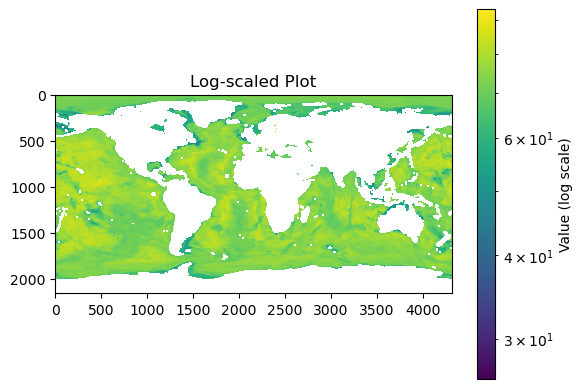

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np


# Plot the array in log scale using plt.imshow
plt.imshow(dataset_numpy_porosity, norm=LogNorm())
plt.colorbar(label='Value (log scale)')  # Add a colorbar with a label
plt.title('Log-scaled Plot')
plt.show()

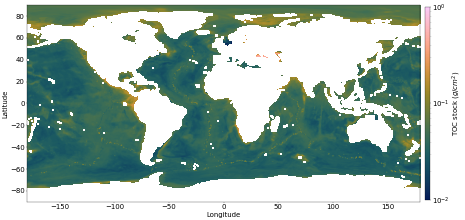

In [9]:
#pm_overlapped[land_map] = np.nan
tocGlobal = (1-(dataset_numpy_porosity/100))*ds*(pm_overlapped/100)*10

#tocGlobal = np.load("mar_c05.npy")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(tocGlobal,norm=LogNorm(vmin=1e-2, vmax=1), cmap=cmc.batlow, extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.01, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC stock ($g/cm^2$)', fontsize=20)
#plt.title("TOC stock", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

In [10]:
np.save("mar_c05.npy", tocGlobal/1000)

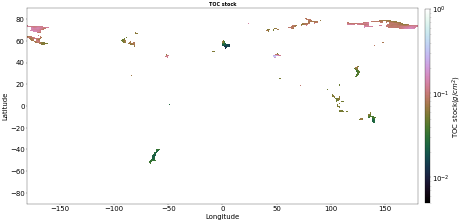

In [11]:
dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))
# Create a copy of tocGlobal_CS
tocGlobal_CS_masked = np.copy(tocGlobal)

# Use boolean indexing to set values to nan where dataset_mask is not nan
tocGlobal_CS_masked[~np.isnan(dataset_mask)] = np.nan

# Now, tocGlobal_CS_masked contains values from tocGlobal_CS where dataset_mask is nan
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(tocGlobal_CS_masked,norm=LogNorm(vmin=5e-3, vmax=1), cmap="cubehelix", extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC stock($g/cm^2$)', fontsize=20)
plt.title("TOC stock", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

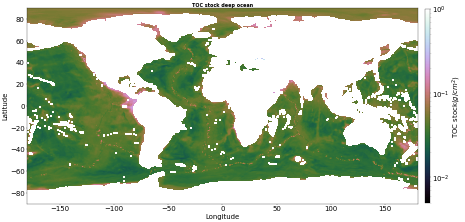

In [12]:
dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_continentalshelves.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))
# Create a copy of tocGlobal_DO
tocGlobal_DO_masked = np.copy(tocGlobal)

# Use boolean indexing to set values to nan where dataset_mask is not nan
tocGlobal_DO_masked[~np.isnan(dataset_mask)] = np.nan

# Now, tocGlobal_DO_masked contains values from tocGlobal_DO where dataset_mask is nan
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(tocGlobal_DO_masked,norm=LogNorm(vmin=5e-3, vmax=1), cmap="cubehelix", extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC stock($g/cm^2$)', fontsize=20)
plt.title("TOC stock deep ocean", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

In [13]:
"""
import matplotlib.pyplot as plt

# Data
constraints = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
num_points = [26915, 26922, 27037, 27133, 27230, 27426, 27908, 27177, 27163, 27403]
total_area = [1.321721375, 1.321920875, 1.327927375, 1.33290725, 1.33792925, 1.348184375, 1.3734495, 1.33521975, 1.334394625, 1.3481215]
total_toc_stock = [19.831775490498355, 19.484104128691328, 20.71898797230301, 19.868475777595734, 19.404769022931376,
                   19.234443080123807, 18.771974249384137, 18.042550031631, 18.466617837876687, 17.951401069313224]

# Plotting
fig, ax1 = plt.subplots()

color = 'tab:red'
ax1.set_xlabel('Constraint')
ax1.set_ylabel('Number of Points', color=color)
ax1.bar(constraints, num_points, color=color, width=0.05)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(26800)  # Set y-limits to start from zero


ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Total Area (million km2)', color=color)
ax2.plot(constraints, total_area, color=color)
ax2.tick_params(axis='y', labelcolor=color)


fig.tight_layout()
plt.title('Number of Points and Total Area with Constraints')
plt.show()

# Plotting TOC Stock
plt.figure()
plt.bar(constraints, total_toc_stock, color='green', width=0.05)
plt.xlabel('Constraint')
plt.ylim(17)  # Set y-limits to start from zero
plt.ylabel('Total TOC Stock (GT)')
plt.title('Total TOC Stock with Constraints')
plt.show()
"""

"\nimport matplotlib.pyplot as plt\n\n# Data\nconstraints = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]\nnum_points = [26915, 26922, 27037, 27133, 27230, 27426, 27908, 27177, 27163, 27403]\ntotal_area = [1.321721375, 1.321920875, 1.327927375, 1.33290725, 1.33792925, 1.348184375, 1.3734495, 1.33521975, 1.334394625, 1.3481215]\ntotal_toc_stock = [19.831775490498355, 19.484104128691328, 20.71898797230301, 19.868475777595734, 19.404769022931376,\n                   19.234443080123807, 18.771974249384137, 18.042550031631, 18.466617837876687, 17.951401069313224]\n\n# Plotting\nfig, ax1 = plt.subplots()\n\ncolor = 'tab:red'\nax1.set_xlabel('Constraint')\nax1.set_ylabel('Number of Points', color=color)\nax1.bar(constraints, num_points, color=color, width=0.05)\nax1.tick_params(axis='y', labelcolor=color)\nax1.set_ylim(26800)  # Set y-limits to start from zero\n\n\nax2 = ax1.twinx()\ncolor = 'tab:blue'\nax2.set_ylabel('Total Area (million km2)', color=color)\nax2.plot(constraints, total_

In [14]:
"""
import matplotlib.pyplot as plt

# Provided data
constraints = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
num_points = [27403, 26915, 26922, 27037, 27133, 27230, 27426, 27908, 27177, 27163, 27403]
total_area = [1.3481215, 1.321721375, 1.321920875, 1.327927375, 1.33290725, 1.33792925, 1.348184375, 1.3734495, 1.33521975, 1.334394625, 1.3481215]
toc_stock_points = [0.0027055620127214423, 0.0004630560561800398, 0.0004944169850267074, 0.001010318319218695, 0.0014346801391991442, 0.001853486156864467, 0.0026755471935713732, 0.004457050409304898, 0.0016307208226443621, 0.0015345318317171249, 0.0027055620127214423]
total_toc_stock = [17.951401069313224, 19.831775490498355, 19.484104128691328, 20.71898797230301, 19.868475777595734, 19.404769022931376, 19.234443080123807, 18.771974249384137, 18.042550031631, 18.466617837876687, 17.951401069313224]

# Plotting
fig, axs = plt.subplots(3, 1, figsize=(10, 15))
"""
"""
# Bar plot for the number of points
axs[0].bar(constraints, num_points, color='blue', alpha=0.7, width=0.05)
axs[0].set_title('Number of Points below 1e-2 g/cm2')
axs[0].set_xlabel('Constraint')
axs[0].set_ylabel('Number of Points')
axs[0].set_ylim(26500, 28000)
"""
# Bar plot for the total area
"""
axs[0].bar(constraints, total_area, color='green', alpha=0.7, width=0.05)
axs[0].set_title('Total Area (million km2) with Points below 1e-2 g/cm2')
axs[0].set_xlabel('Constraint')
axs[0].set_ylabel('Total Area (million km2)')
axs[0].set_ylim(1.3, 1.4)

# Bar plot for TOC stock in regions<200m depth with points below 1e-2
#axs[2].bar(constraints, total_toc_stock, color='red', label='Total', width=0.05)
axs[1].bar(constraints, toc_stock_points, color='green', label='With Points below 1e-2', width=0.05)

axs[1].set_title('Total TOC Stock (GT) with Points below 1e-2 g/cm2 in regions<200m depth')
axs[1].set_xlabel('Constraint')
axs[1].set_ylabel('Total TOC Stock (GT)')
axs[1].legend()

axs[2].bar(constraints, total_toc_stock, color='red', label='Total', width=0.05)

axs[2].set_title('Total TOC Stock (GT) in regions<200m depth')
axs[2].set_xlabel('Constraint')
axs[2].set_ylabel('Total TOC Stock (GT)')
axs[2].legend()
axs[2].set_ylim(17.5, 21.5)

# Adjust layout to prevent clipping
plt.tight_layout()
plt.show()
"""

"\naxs[0].bar(constraints, total_area, color='green', alpha=0.7, width=0.05)\naxs[0].set_title('Total Area (million km2) with Points below 1e-2 g/cm2')\naxs[0].set_xlabel('Constraint')\naxs[0].set_ylabel('Total Area (million km2)')\naxs[0].set_ylim(1.3, 1.4)\n\n# Bar plot for TOC stock in regions<200m depth with points below 1e-2\n#axs[2].bar(constraints, total_toc_stock, color='red', label='Total', width=0.05)\naxs[1].bar(constraints, toc_stock_points, color='green', label='With Points below 1e-2', width=0.05)\n\naxs[1].set_title('Total TOC Stock (GT) with Points below 1e-2 g/cm2 in regions<200m depth')\naxs[1].set_xlabel('Constraint')\naxs[1].set_ylabel('Total TOC Stock (GT)')\naxs[1].legend()\n\naxs[2].bar(constraints, total_toc_stock, color='red', label='Total', width=0.05)\n\naxs[2].set_title('Total TOC Stock (GT) in regions<200m depth')\naxs[2].set_xlabel('Constraint')\naxs[2].set_ylabel('Total TOC Stock (GT)')\naxs[2].legend()\naxs[2].set_ylim(17.5, 21.5)\n\n# Adjust layout to p

In [15]:
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

In [16]:
tocGlobal_CS_masked.shape

(2160, 4320)

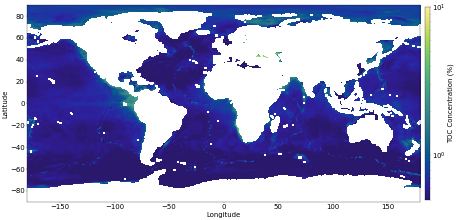

In [17]:

tocGlobal = (1-(dataset_numpy_porosity/100))*ds*(pm_overlapped/100)*10
pm_overlapped[land_map] = np.nan
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(pm_overlapped,norm=LogNorm(vmin=5e-1, vmax=10), cmap=cmo.cm.haline, extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC Concentration[%]', aspect=40, pad=0.01, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC Concentration (%)', fontsize=20)
#plt.title("TOC [%]", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

In [18]:
np.save("tocConcentration.npy", pm_overlapped)

In [19]:
tocConc = np.load("tocConcentration.npy")
mar = np.load("mar_c05.npy")
burialrate = np.multiply(tocConc, mar)

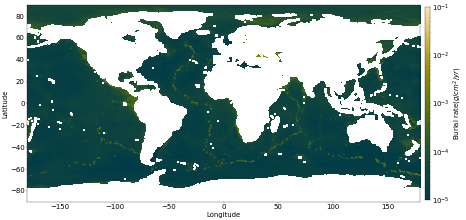

In [20]:
# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(burialrate,norm=LogNorm(vmin=1e-5, vmax=1e-1), cmap=cmc.bamako, extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC Concentration[%]', aspect=40, pad=0.01, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('Burial rate($g/cm^2/yr$)', fontsize=20)
#plt.title("TOC [%]", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

In [21]:
np.nanmin(pm_overlapped)

0.07220345188700485

In [22]:
import scipy.io

# Assuming pm_overlapped is a NumPy array
data = {'pm_overlapped': pm_overlapped}

# Specify the path where you want to save the .mat file
mat_file_path = 'toc_noconstraint.mat'

# Save the data to a MATLAB .mat file
scipy.io.savemat(mat_file_path, data)

In [23]:
#feature_image_path ="/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/"
restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
#restrepo_features_path_flipped = Path("/media/sunms498/EXTERNAL_USB/Features_Phrampus_flipped")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']

# restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
# restrepo_features[:] = np.nan
# restrepo_X_mean = np.empty(0)
# restrepo_X_std = np.empty(0)

file_idx = -1
corrupted_files = 0


 
rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')


    
#     latitudes = rootgrp.variables['lats'] # in theory all the same
#     longitudes = rootgrp.variables['lons']

dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi)



In [24]:
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
tocGlobal_g = np.multiply(tocGlobal,area_np)*1e10 # in g

In [25]:
np.nansum(tocGlobal_g/1e15)

172.651889351182

In [26]:
# Assuming tocGlobal_CS_masked is already defined
condition_mask = tocGlobal_CS_masked < 1e-2

# Count the number of True values in the condition_mask
num_points_below_threshold = np.count_nonzero(condition_mask)

print("Number of points below 1e-2:", num_points_below_threshold)

# Use boolean indexing to select areas where the condition is True
selected_areas = area_np[condition_mask]
selected_areas_true = np.where(condition_mask, area_np, np.nan)
# Sum the selected areas
total_area_below_threshold = np.sum(selected_areas)

print("Total area(million km2) with points below 1e-2:", total_area_below_threshold/1e6)

tocGlobal_g_CS_selected_areas = np.multiply(tocGlobal_CS_masked,selected_areas_true)*1e10 # in g/cm²

print("Total TOC stock(GT) in regions<200m depth with points below 1e-2:", np.nansum(tocGlobal_g_CS_selected_areas/1e15))

tocGlobal_g_CS = np.multiply(tocGlobal_CS_masked,area_np)*1e10 # in g/cm²

print("Total TOC stock(GT) in regions<200m depth:", np.nansum(tocGlobal_g_CS/1e15))


Number of points below 1e-2: 27953
Total area(million km2) with points below 1e-2: 1.37610725
Total TOC stock(GT) in regions<200m depth with points below 1e-2: 0.004511093583117469
Total TOC stock(GT) in regions<200m depth: 19.964036602766615


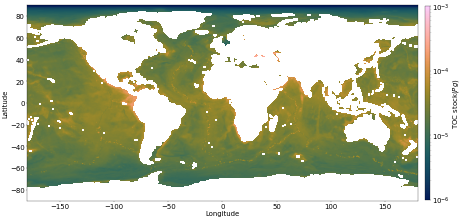

In [27]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(tocGlobal_g/1e15,norm=LogNorm(vmin=1e-6, vmax=1e-3), cmap=cmc.batlow, extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC stock($Pg$)', fontsize=20)
#plt.title("TOC stock cell wise", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

In [28]:
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
tocPercent_cellwise = np.multiply(pm_overlapped,area_np) # in % km²

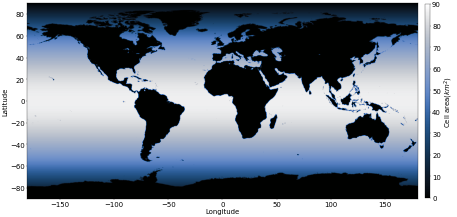

In [29]:
area_np_land = area_np
area_np_land[land_map]= 0
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(area_np_land, vmax = 90,  cmap=cmc.oslo, extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='Area (km^2)', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('Cell area($km^2$)', fontsize=20)
#plt.title("Cell area", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

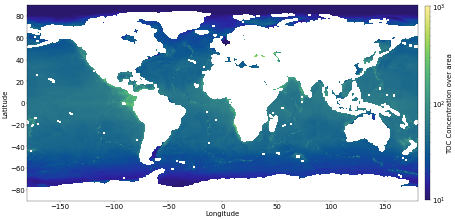

In [30]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(tocPercent_cellwise,norm=LogNorm(vmin=1e1, vmax=1e3), cmap=cmo.cm.haline, extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC Concentration over area', fontsize=20)
#plt.title("TOC Percent cell wise", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

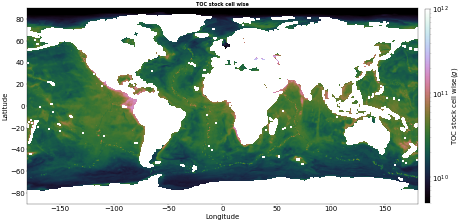

In [31]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(tocGlobal_g,norm=LogNorm(vmin=5e9, vmax=1e12), cmap="cubehelix", extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC stock cell wise($g$)', fontsize=20)
plt.title("TOC stock cell wise", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

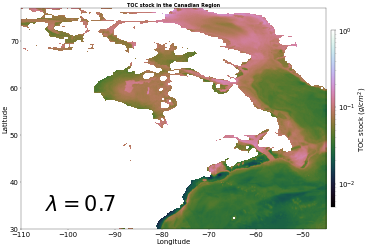

In [32]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Define the extent for the Canadian region
canadian_extent = [-110, -45, 30, 77]

# Generate some example data for demonstration
tocGlobal = (1 - (dataset_numpy_porosity / 100)) * ds * (pm_overlapped / 100) * 10

# Get the latitude and longitude values for indexing
latitude_values = np.linspace(90, -90, tocGlobal.shape[0])
longitude_values = np.linspace(-180, 180, tocGlobal.shape[1])

# Find the indices for the Canadian region
canadian_extent_lat_indices = np.where((latitude_values >= canadian_extent[2]) & 
                                   (latitude_values <= canadian_extent[3]))

canadian_extent_lon_indices = np.where((longitude_values >= canadian_extent[0]) & 
                                       (longitude_values <= canadian_extent[1]))

# Extract the Canadian region from tocGlobal
tocGlobal_canadian = tocGlobal[canadian_extent_lat_indices[0][0]:canadian_extent_lat_indices[0][-1] + 1,
                               canadian_extent_lon_indices[0][0]:canadian_extent_lon_indices[0][-1] + 1]

np.save("tocCanadaconstraint05.npy", tocGlobal_canadian)

plt.figure(figsize=(20, 10), dpi = 25)
# Set the extent parameter to focus on the Canadian region
plt.imshow(tocGlobal_canadian, norm=LogNorm(vmin=5e-3, vmax=1), cmap="cubehelix", extent=canadian_extent)

# Add color bar
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.01, shrink=0.8)
cbar.ax.tick_params(labelsize=20)
cbar.set_label('TOC stock ($g/cm^2$)', fontsize=20)

# Set title and labels
plt.title("TOC stock in the Canadian Region", fontsize=14, fontweight='bold')
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)

# Add "lambda = 0" to the left bottom corner
plt.text(-105, 33, r'$\lambda = 0.7$', fontsize=60, color='black', ha='left', va='bottom')

# Adjust font size for ticks
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)

# Show the plot
plt.tight_layout()
plt.show()

In [33]:
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Folder path where the NumPy files are stored
# folder_path = '/path/to/your/folder'

# List of constraint values
constraints = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

# Create subplots with shared longitude axes
fig, axs = plt.subplots(3, 2, figsize=(15, 15), dpi = 25, sharex='col', sharey='row')
fig.subplots_adjust(hspace=0, wspace=0)

# Loop through each constraint value
for i, constraint in enumerate(constraints):
    # Load the corresponding NumPy file
    file_path = os.path.join(f'tocCanadaconstraint0{int(constraint*10)}.npy')
    tocGlobal_canadian = np.load(file_path)

    # Plot the data
    im = axs[i // 2, i % 2].imshow(tocGlobal_canadian, norm=LogNorm(vmin=5e-3, vmax=3) , cmap="cubehelix", extent=canadian_extent)
    #norm=LogNorm(vmin=5e-3, vmax=1)
    # Set title and labels
    # axs[i // 2, i % 2].set_title(f"TOC stock, λ = {constraint:.1f}", fontsize=10, fontweight='bold')
    #axs[i // 2, i % 2].set_xlabel("Latitude", fontsize=10)

    # Add constraint value as text
    axs[i // 2, i % 2].text(-109, 33, fr'$\lambda = {constraint:.1f}$', fontsize=40, color='black', ha='left', va='bottom')

    # Show ylabel only on plots for constraints 0.4 and 0.5
    if constraint in [0.4, 0.5]:
        axs[i // 2, i % 2].set_xlabel("Longitude", fontsize=20)
        
    if constraint in [0.0, 0.2, 0.4]:
        axs[i // 2, i % 2].set_ylabel("Latitude", fontsize=20)

# Adjust font size for ticks
for ax in axs.flat:
    ax.tick_params(axis='both', labelsize=20)
    
    
fig.subplots_adjust(right=0.8)
cax = fig.add_axes([1.0, 0.15, 0.02, 0.8])
cbar = fig.colorbar(im, cax=cax, aspect=40, pad=0.015, shrink=0.8)
cbar.set_label("TOC [%]", size = 20)
cbar.ax.tick_params(labelsize=20)


plt.tight_layout()
plt.show()
"""

'\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom matplotlib.colors import LogNorm\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\n\n# Folder path where the NumPy files are stored\n# folder_path = \'/path/to/your/folder\'\n\n# List of constraint values\nconstraints = [0, 0.1, 0.2, 0.3, 0.4, 0.5]\n\n# Create subplots with shared longitude axes\nfig, axs = plt.subplots(3, 2, figsize=(15, 15), dpi = 25, sharex=\'col\', sharey=\'row\')\nfig.subplots_adjust(hspace=0, wspace=0)\n\n# Loop through each constraint value\nfor i, constraint in enumerate(constraints):\n    # Load the corresponding NumPy file\n    file_path = os.path.join(f\'tocCanadaconstraint0{int(constraint*10)}.npy\')\n    tocGlobal_canadian = np.load(file_path)\n\n    # Plot the data\n    im = axs[i // 2, i % 2].imshow(tocGlobal_canadian, norm=LogNorm(vmin=5e-3, vmax=3) , cmap="cubehelix", extent=canadian_extent)\n    #norm=LogNorm(vmin=5e-3, vmax=1)\n    # Set title and labels\n    # axs[i // 2, i % 2].se

In [34]:
"""
import scipy.io
data_to_save = {'toc_percent': pm_overlapped}
scipy.io.savemat('tocpercent.mat', data_to_save)
"""

"\nimport scipy.io\ndata_to_save = {'toc_percent': pm_overlapped}\nscipy.io.savemat('tocpercent.mat', data_to_save)\n"

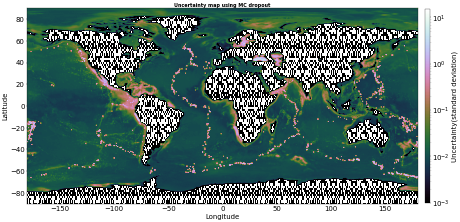

In [35]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(um_overlapped,norm=LogNorm(vmin=1e-3, vmax=15), cmap="cubehelix", extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('Uncertainty(standard deviation)', fontsize=20)
plt.title("Uncertainty map using MC dropout", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

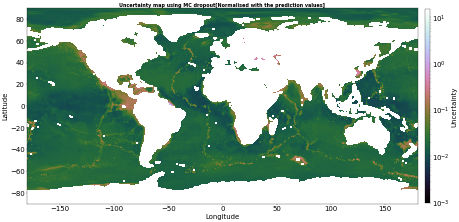

In [36]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi = 25)
plt.imshow(um_overlapped/pm_overlapped,norm=LogNorm(vmin=1e-3, vmax=15), cmap="cubehelix", extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('Uncertainty', fontsize=20)
plt.title("Uncertainty map using MC dropout[Normalised with the prediction values]", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi = 25)

plt.show()

In [37]:
"""
df3_DO = pd.read_csv("/gxfs_work/cau/sunms498/work/nn4sedratetoc/notebooks/TOC/difference_DO_file.csv")
df3_CS = pd.read_csv("/gxfs_work/cau/sunms498/work/nn4sedratetoc/notebooks/TOC/difference_CS_file.csv")

df3 = pd.concat([df3_DO, df3_CS], ignore_index=True)

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from matplotlib.colors import LogNorm
# Assuming df3 is your DataFrame
# Replace df3 with your actual DataFrame

# Create a GeoDataFrame from df3
geometry = [Point(xy) for xy in zip(df3['Longitude'], df3['Latitude'])]
gdf = gpd.GeoDataFrame(df3, geometry=geometry)

# Plotting
fig, ax = plt.subplots(figsize=(20, 10), dpi = 25)  # Adjust the figsize as needed

# Plotting the world map
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
world.plot(ax=ax, alpha=0.5, color='grey')

# Scatter plot for differences with colors representing the differences
# Scatter plot for differences with log-scaled colors in the scatter plot
scatter = ax.scatter(
    gdf['Longitude'],
    gdf['Latitude'],
    c=abs(gdf['Difference']),
    cmap='gnuplot2',
    #vmin = -5, vmax = 5,
    norm=LogNorm(vmin = 1e-3, vmax = 1e2),  # Applying log scale to the scatter plot
    s=5
    
)
plt.tight_layout()
plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlim([-180, 180])
plt.ylim([-90, 90])
# Add a colorbar with the original differences in log scale
cbar = plt.colorbar(scatter)

cbar.set_label('Absolute difference')

# Set labels and title
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.title("Difference between model predictions and actual measurements")
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
plt.show()
"""

'\ndf3_DO = pd.read_csv("/gxfs_work/cau/sunms498/work/nn4sedratetoc/notebooks/TOC/difference_DO_file.csv")\ndf3_CS = pd.read_csv("/gxfs_work/cau/sunms498/work/nn4sedratetoc/notebooks/TOC/difference_CS_file.csv")\n\ndf3 = pd.concat([df3_DO, df3_CS], ignore_index=True)\n\nimport geopandas as gpd\nimport matplotlib.pyplot as plt\nfrom shapely.geometry import Point\nfrom matplotlib.colors import LogNorm\n# Assuming df3 is your DataFrame\n# Replace df3 with your actual DataFrame\n\n# Create a GeoDataFrame from df3\ngeometry = [Point(xy) for xy in zip(df3[\'Longitude\'], df3[\'Latitude\'])]\ngdf = gpd.GeoDataFrame(df3, geometry=geometry)\n\n# Plotting\nfig, ax = plt.subplots(figsize=(20, 10), dpi = 25)  # Adjust the figsize as needed\n\n# Plotting the world map\nworld = gpd.read_file(gpd.datasets.get_path(\'naturalearth_lowres\'))\nworld.plot(ax=ax, alpha=0.5, color=\'grey\')\n\n# Scatter plot for differences with colors representing the differences\n# Scatter plot for differences with log-s

In [38]:
import geopandas as gpd
from rasterio.features import geometry_mask
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Assuming 'mar_naveen_nonan' is your prediction map and 'ocean_gdf' is the GeoDataFrame of ocean boundaries
# Ensure 'mar_naveen_nonan' has the same resolution as the ocean boundaries map

# Assuming 'mar_naveen_nonan' is a NumPy array with shape (2160, 4320)
resolution = 5 / 60  # 5 arc minutes in degrees
lon = np.arange(-180, 180, resolution)
lat = np.arange(-90, 90, resolution)

tocGlobal_g_rot = np.rot90(np.rot90(np.fliplr(tocGlobal_g)))

# Create a GeoDataFrame with the prediction values and their corresponding geometry
lon_mesh, lat_mesh = np.meshgrid(lon, lat)
prediction_gdf = gpd.GeoDataFrame(
    data={'TOC': tocGlobal_g_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)

In [39]:
import geopandas as gpd
from rasterio.features import geometry_mask
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Assuming 'mar_naveen_nonan' is your prediction map and 'ocean_gdf' is the GeoDataFrame of ocean boundaries
# Ensure 'mar_naveen_nonan' has the same resolution as the ocean boundaries map

# Assuming 'mar_naveen_nonan' is a NumPy array with shape (2160, 4320)
resolution = 5 / 60  # 5 arc minutes in degrees
lon = np.arange(-180, 180, resolution)
lat = np.arange(-90, 90, resolution)


tocPercent_cellwise_rot = np.rot90(np.rot90(np.fliplr(tocPercent_cellwise)))
# Create a GeoDataFrame with the prediction values and their corresponding geometry
lon_mesh, lat_mesh = np.meshgrid(lon, lat)
tocPercentcCellwise_gdf = gpd.GeoDataFrame(
    data={'TOCPercent': tocPercent_cellwise_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)

In [40]:
import geopandas as gpd
from rasterio.features import geometry_mask
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Assuming 'mar_naveen_nonan' is your prediction map and 'ocean_gdf' is the GeoDataFrame of ocean boundaries
# Ensure 'mar_naveen_nonan' has the same resolution as the ocean boundaries map

# Assuming 'mar_naveen_nonan' is a NumPy array with shape (2160, 4320)
resolution = 5 / 60  # 5 arc minutes in degrees
lon = np.arange(-180, 180, resolution)
lat = np.arange(-90, 90, resolution)
area_np_land_rot = np.rot90(np.rot90(np.fliplr(area_np_land)))
# Create a GeoDataFrame with the prediction values and their corresponding geometry
lon_mesh, lat_mesh = np.meshgrid(lon, lat)
area_gdf = gpd.GeoDataFrame(
    data={'area': np.array(area_np_land_rot).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)

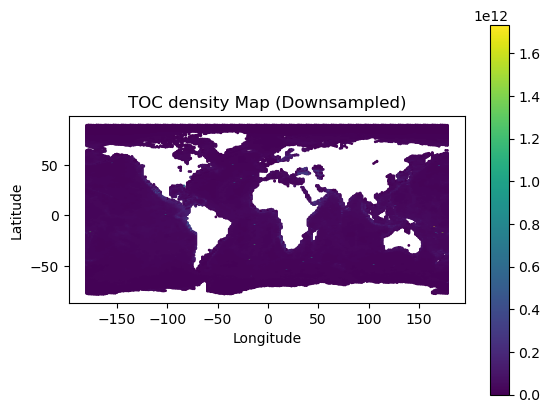

In [41]:
# Downsample the GeoDataFrame by taking every nth point
n = 100  # Adjust this value based on your desired level of downsampling
downsampled_gdf = prediction_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='TOC', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC density Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

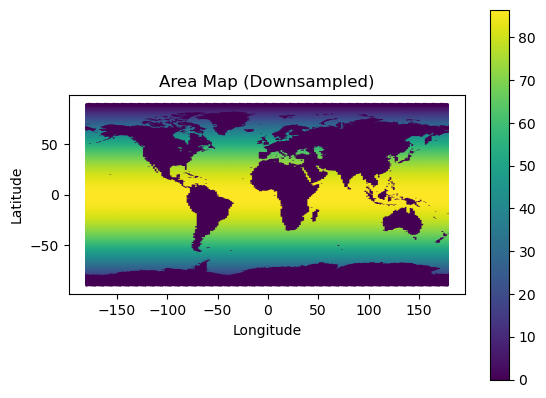

In [42]:
# Downsample the GeoDataFrame by taking every nth point
n = 100  # Adjust this value based on your desired level of downsampling
downsampled_gdf = area_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='area', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Area Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

In [43]:
ocean_gdf = gpd.read_file('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/GOaS_v1_20211214/goas_v01.shp')

<Axes: >

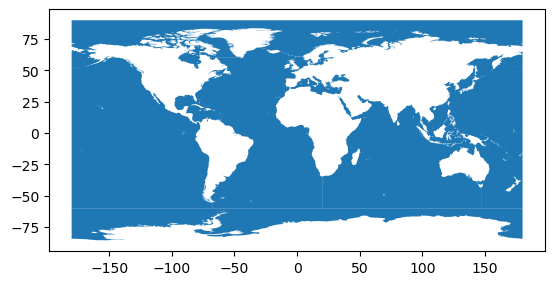

In [44]:
ocean_gdf.plot()

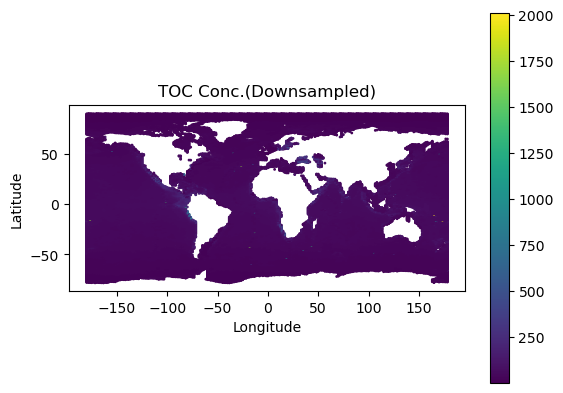

In [45]:
# Downsample the GeoDataFrame by taking every nth point
n = 100  # Adjust this value based on your desired level of downsampling
downsampled_gdf = tocPercentcCellwise_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='TOCPercent', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC Conc.(Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

In [46]:
ocean_gdf

,name,latitude,longitude,min_Y,min_X,max_Y,max_X,area_km2,geometry
0,Southern Ocean,-68.03985,-26.63275,-85.56250,-180.00000,-60.00000,180.00000,6793589,"POLYGON ((180.00000 -60.00000, 180.00000 -84.3..."
1,South Atlantic Ocean,-33.73758,-18.83411,-60.00000,-69.60084,0.07511,20.00000,42815540,"MULTIPOLYGON (((-50.68008 0.00000, -50.64339 0..."
2,South Pacific Ocean,-30.09612,-143.06088,-60.00000,130.11129,3.39114,-67.26667,90147400,"MULTIPOLYGON (((-70.93199 -54.75580, -70.92427..."
3,North Pacific Ocean,26.95013,-169.38334,0.00000,117.51622,66.56286,-76.98544,77124830,"MULTIPOLYGON (((157.14844 57.76842, 157.15257 ..."
4,South China and Easter Archipelagic Seas,5.62943,115.46548,-10.92259,95.43328,25.56728,134.03155,6822162,"MULTIPOLYGON (((119.28261 25.48829, 119.27451 ..."
5,Indian Ocean,-27.27272,79.60241,-60.00000,20.00000,31.18586,146.91671,78162363,"MULTIPOLYGON (((56.08700 27.10831, 56.08874 27..."
6,Mediterranean Region,38.13065,19.70067,30.06809,-6.03255,47.37640,42.35496,2988248,"POLYGON ((32.57319 30.06809, 32.56996 30.06817..."
7,Baltic Sea,58.78478,19.22115,52.65352,9.36560,67.08059,30.34710,415600,"POLYGON ((27.35543 60.48886, 27.35988 60.48797..."
8,North Atlantic Ocean,31.77621,-40.24758,-0.93603,-98.05392,68.63872,12.00594,41741693,"MULTIPOLYGON (((-29.42622 68.22895, -23.13435 ..."
9,Arctic Ocean,79.14792,-3.28568,51.14359,-180.00000,90.00000,180.00000,15571669,"MULTIPOLYGON (((178.29612 69.42748, 178.29961 ..."


In [47]:
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf = gpd.sjoin(prediction_gdf, ocean_gdf, op='within')

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


In [48]:
joined_area_gdf = gpd.sjoin(area_gdf, ocean_gdf, op='within')

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


In [56]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC  in {ocean_name}: {toc_sum/1e15} Pg")

Sum of TOC  in Arctic Ocean: 12.217038190380666 Pg
Sum of TOC  in Baltic Sea: 0.8404742125136337 Pg
Sum of TOC  in Indian Ocean: 32.34517572508457 Pg
Sum of TOC  in Mediterranean Region: 2.762550608040676 Pg
Sum of TOC  in North Atlantic Ocean: 19.620813077402392 Pg
Sum of TOC  in North Pacific Ocean: 36.33577145266614 Pg
Sum of TOC  in South Atlantic Ocean: 16.624558570925497 Pg
Sum of TOC  in South China and Easter Archipelagic Seas: 4.211153630019358 Pg
Sum of TOC  in South Pacific Ocean: 37.91271689315057 Pg
Sum of TOC  in Southern Ocean: 7.828277184581835 Pg


In [50]:
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf_tocPercent = gpd.sjoin(tocPercentcCellwise_gdf, ocean_gdf, op='within')

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


In [51]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf_tocPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC Percent in {ocean_name}: {toc_sum/1e6} %km2 (x1e6)")

Sum of TOC Percent in Arctic Ocean: 13.315903332332743 %km2 (x1e6)
Sum of TOC Percent in Baltic Sea: 1.3203352895834106 %km2 (x1e6)
Sum of TOC Percent in Indian Ocean: 45.43502968468842 %km2 (x1e6)
Sum of TOC Percent in Mediterranean Region: 3.309049574595362 %km2 (x1e6)
Sum of TOC Percent in North Atlantic Ocean: 27.10807830591804 %km2 (x1e6)
Sum of TOC Percent in North Pacific Ocean: 55.94043351197328 %km2 (x1e6)
Sum of TOC Percent in South Atlantic Ocean: 25.210802411855052 %km2 (x1e6)
Sum of TOC Percent in South China and Easter Archipelagic Seas: 4.7320754645333665 %km2 (x1e6)
Sum of TOC Percent in South Pacific Ocean: 55.254969137085936 %km2 (x1e6)
Sum of TOC Percent in Southern Ocean: 10.726526693726335 %km2 (x1e6)


In [52]:
# Calculate the sum of TOC in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of {ocean_name}: {area/1e6} million km^2")

Area of Arctic Ocean: 15.185819 million km^2
Area of Baltic Sea: 0.392735125 million km^2
Area of Indian Ocean: 71.160768 million km^2
Area of Mediterranean Region: 2.91881925 million km^2
Area of North Atlantic Ocean: 41.721284 million km^2
Area of North Pacific Ocean: 77.248968 million km^2
Area of South Atlantic Ocean: 40.530364 million km^2
Area of South China and Easter Archipelagic Seas: 6.7387235 million km^2
Area of South Pacific Ocean: 85.270424 million km^2
Area of Southern Ocean: 20.73395 million km^2


In [53]:
# the total toc in the oceans is 101.97 GT

In [54]:
"""
# Assuming you have the sum of TOC values for each ocean
sum_of_toc_values = [5.231562372377745, 0.1872689084057434, 24.382676355920573, 1.3947872646266892,
                      13.519289941250232, 33.147472435949844, 15.271901411364151, 4.058322859389308,
                      36.711669869873255, 19.939924322796493]

# Create a DataFrame from the provided data
data = {
    'name': ['Southern Ocean', 'South Atlantic Ocean', 'South Pacific Ocean', 'North Pacific Ocean',
             'South China and Easter Archipelagic Seas', 'Indian Ocean', 'Mediterranean Region',
             'Baltic Sea', 'North Atlantic Ocean', 'Arctic Ocean'],
    'area_km2': [6793589, 42815540, 90147400, 77124830, 6822162, 78162363, 2988248, 415600, 41741693, 15571669],
    'sum_of_toc': sum_of_toc_values
}
ocean_summary_table = pd.DataFrame(data)

# Display the table
print(ocean_summary_table)
"""

"\n# Assuming you have the sum of TOC values for each ocean\nsum_of_toc_values = [5.231562372377745, 0.1872689084057434, 24.382676355920573, 1.3947872646266892,\n                      13.519289941250232, 33.147472435949844, 15.271901411364151, 4.058322859389308,\n                      36.711669869873255, 19.939924322796493]\n\n# Create a DataFrame from the provided data\ndata = {\n    'name': ['Southern Ocean', 'South Atlantic Ocean', 'South Pacific Ocean', 'North Pacific Ocean',\n             'South China and Easter Archipelagic Seas', 'Indian Ocean', 'Mediterranean Region',\n             'Baltic Sea', 'North Atlantic Ocean', 'Arctic Ocean'],\n    'area_km2': [6793589, 42815540, 90147400, 77124830, 6822162, 78162363, 2988248, 415600, 41741693, 15571669],\n    'sum_of_toc': sum_of_toc_values\n}\nocean_summary_table = pd.DataFrame(data)\n\n# Display the table\nprint(ocean_summary_table)\n"

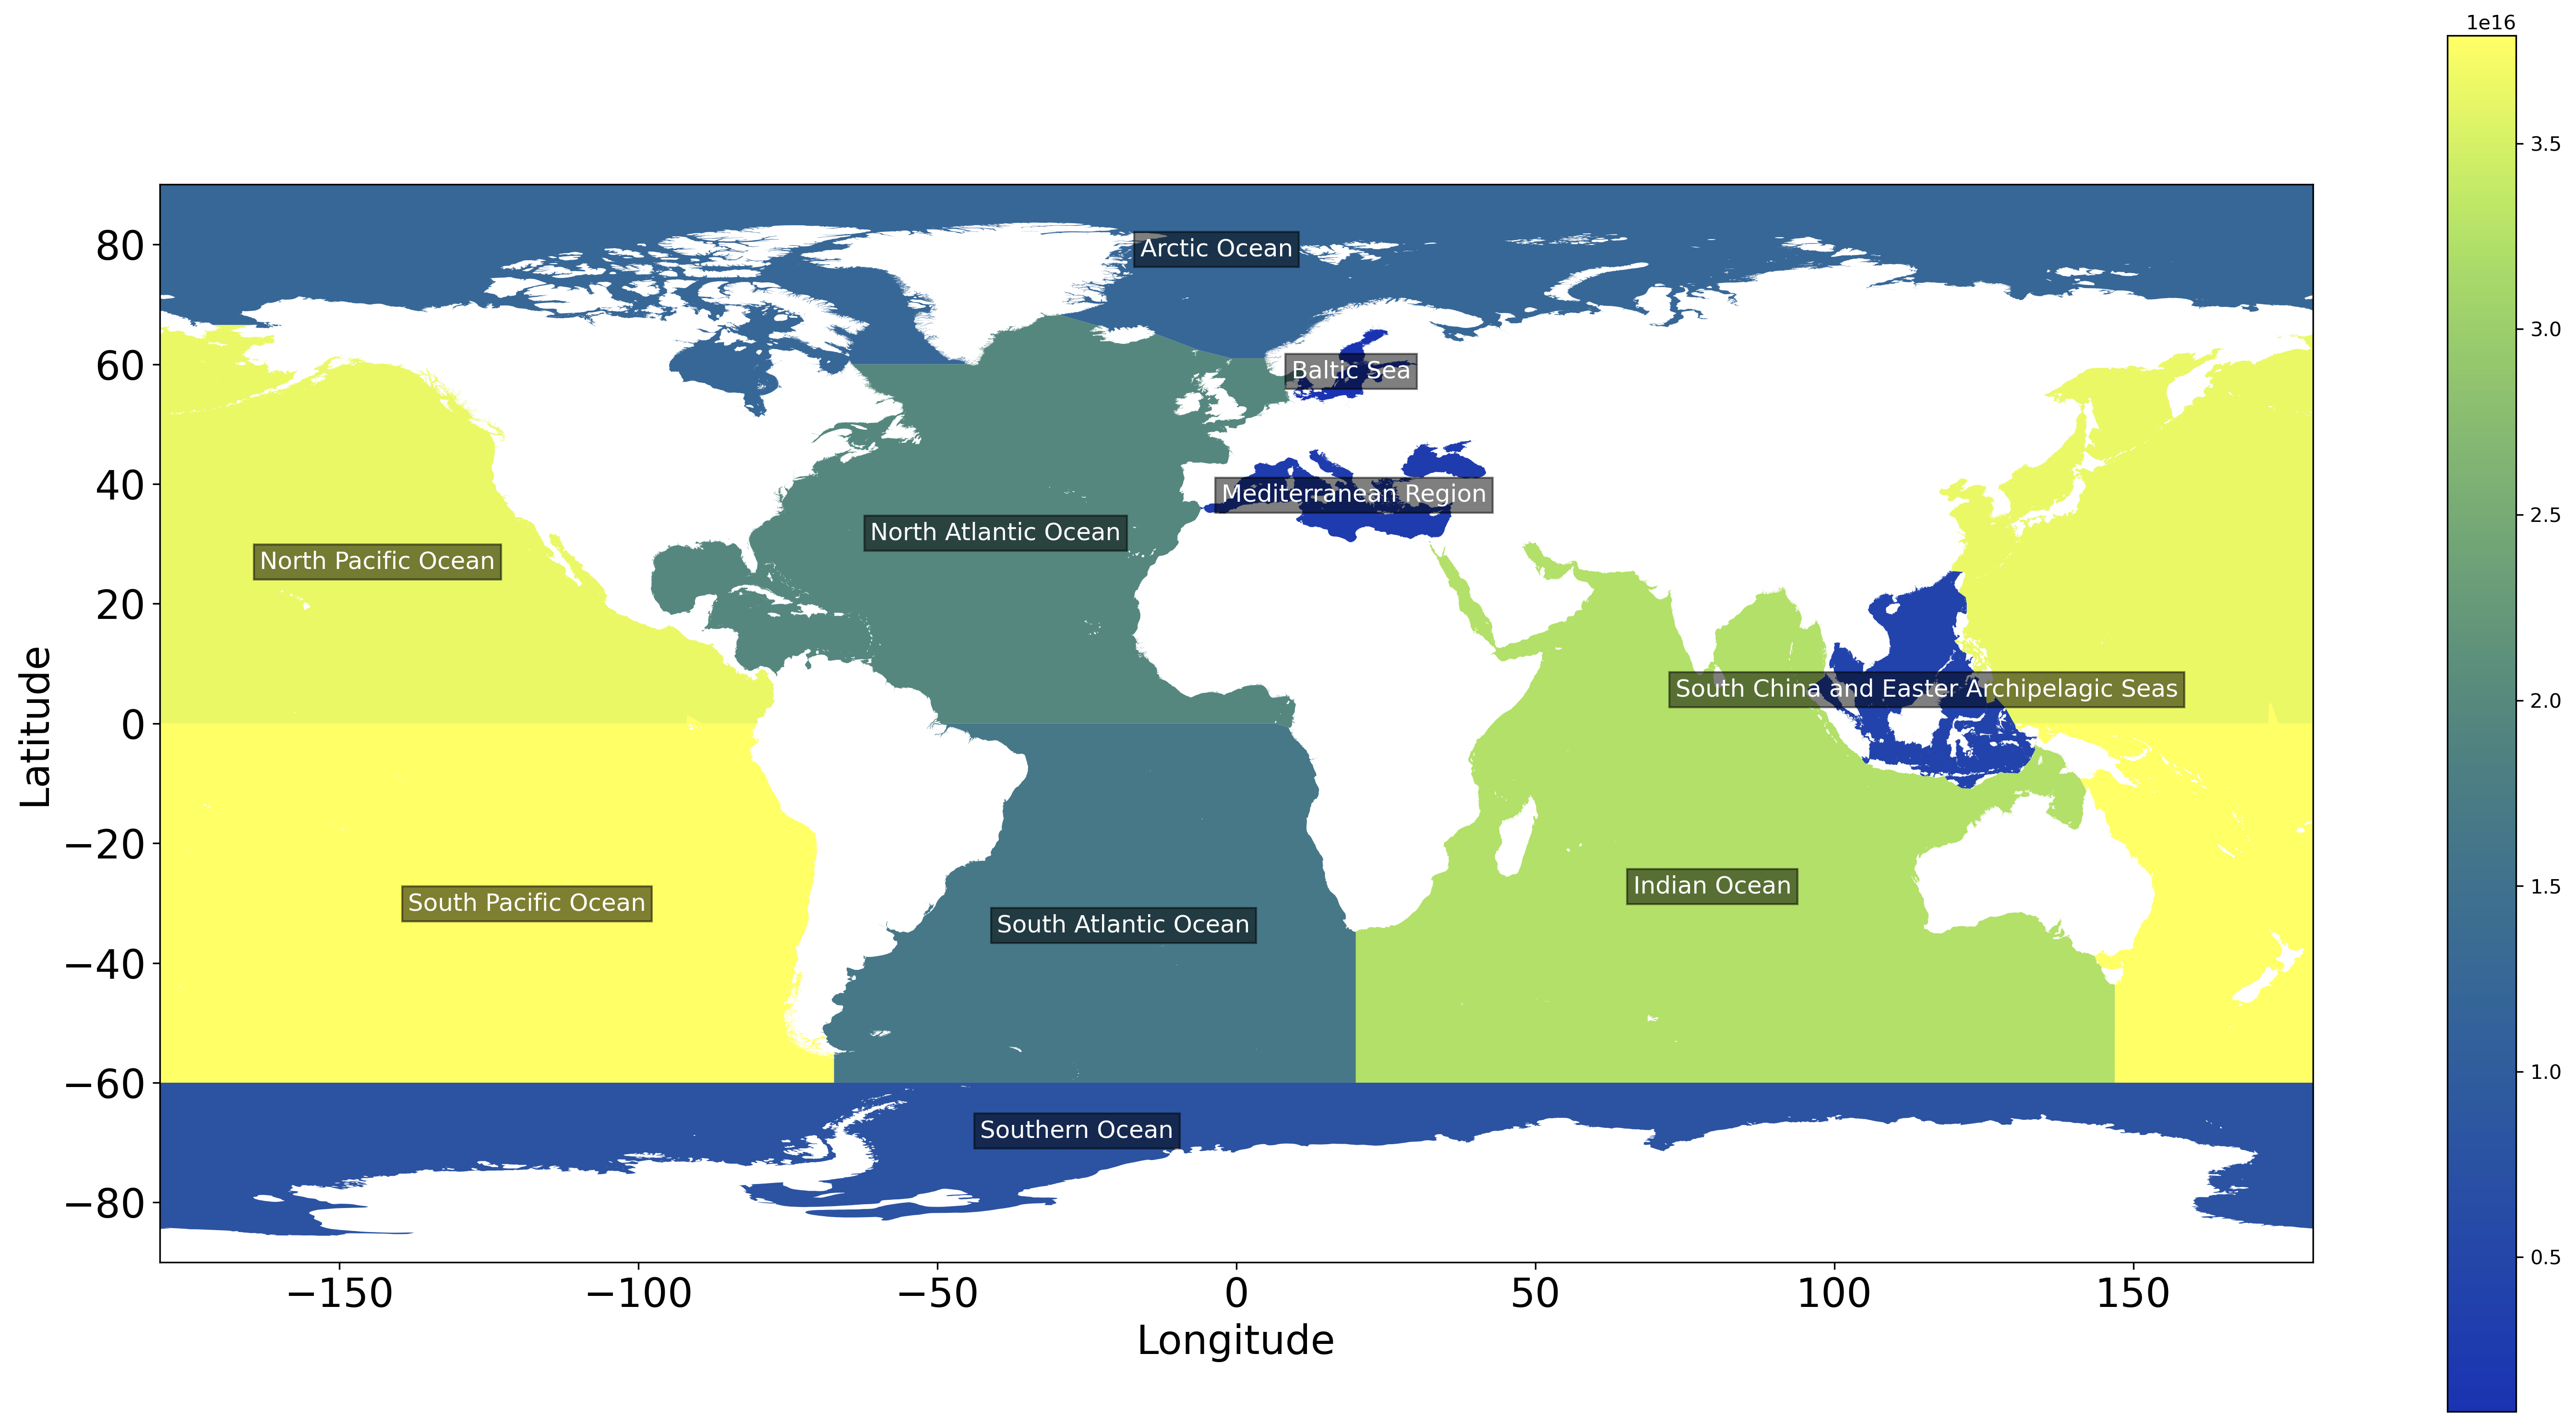

In [58]:

import cmcrameri.cm as cmc

# Merge the sum of TOC data with the ocean GeoDataFrame
merged_gdf = ocean_gdf.merge(sum_toc_by_polygon, left_on='name', right_index=True)
# Plot the GeoDataFrame with colored polygons
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
merged_gdf.plot(column='TOC', cmap=cmc.imola, legend=True, ax=ax)

# Add legend and set axis labels
ax.set_xlabel('Longitude', fontsize=20)
ax.set_ylabel('Latitude', fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlim([-180, 180])
plt.ylim([-90, 90])

# Add ocean names as text at the centroids of polygons
for idx, row in merged_gdf.iterrows():
    centroid = row.geometry.centroid
    if row['name'] in ['South Pacific Ocean']:
        plt.text(centroid.x * 2, centroid.y, row['name'], fontsize=12, ha='center', va='center', color='white',
                 bbox=dict(facecolor='black', alpha=0.5, pad=3))  # Adjust the pad value for text padding
    elif row['name'] in ['North Pacific Ocean']:
        plt.text(centroid.x * 7.5, centroid.y, row['name'], fontsize=12, ha='center', va='center', color='white',
                 bbox=dict(facecolor='black', alpha=0.5, pad=3))  # Adjust the pad value for text padding
    else:
        plt.text(centroid.x, centroid.y, row['name'], fontsize=12, ha='center', va='center', color='white',
                 bbox=dict(facecolor='black', alpha=0.5, pad=3))  # Adjust the pad value for text padding

# Show the plot
plt.tight_layout()
plt.show()


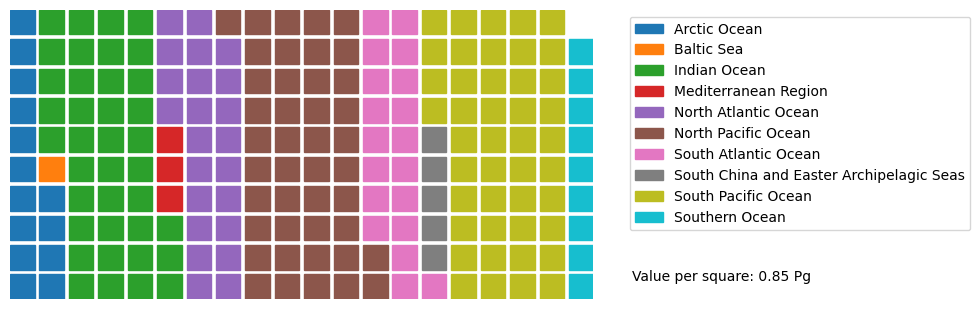

In [94]:
import matplotlib.pyplot as plt
from pywaffle import Waffle

# Define the TOC stock for each ocean
toc_stock = {
    'Arctic Ocean': 1.221704e+16,
    'Baltic Sea': 8.404742e+14,
    'Indian Ocean': 3.234518e+16,
    'Mediterranean Region': 2.762551e+15,
    'North Atlantic Ocean': 1.962081e+16,
    'North Pacific Ocean': 3.633577e+16,
    'South Atlantic Ocean': 1.662456e+16,
    'South China and Easter Archipelagic Seas': 4.211154e+15,
    'South Pacific Ocean': 3.791272e+16,
    'Southern Ocean': 7.828277e+15
}

# Calculate the total TOC stock
total_toc_stock = sum(toc_stock.values())

# Define the number of rows and columns for the waffle chart
rows = 10
columns = 20

# Calculate the total number of squares
total_squares = rows * columns

# Calculate the value represented by each square
value_per_square = total_toc_stock / total_squares

# Create a colorblind-friendly color palette
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
          '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

# Create a waffle chart
plt.figure(figsize = (10,10),
    FigureClass=Waffle,
    rows=10,
    columns=20,
    colors = colors, 
    values=toc_stock,
    legend={'loc': 'upper left', 'bbox_to_anchor': (1.05, 1)}
)
plt.text(2.15, 0.1, f'Value per square: {value_per_square/1e15:.2} Pg', ha='left', va='top')

plt.show()

#plt.title('Waffle Chart of Total Organic Carbon (TOC) Stock by Ocean')
plt.show()


In [66]:
total_toc_stock

1.706985362e+17

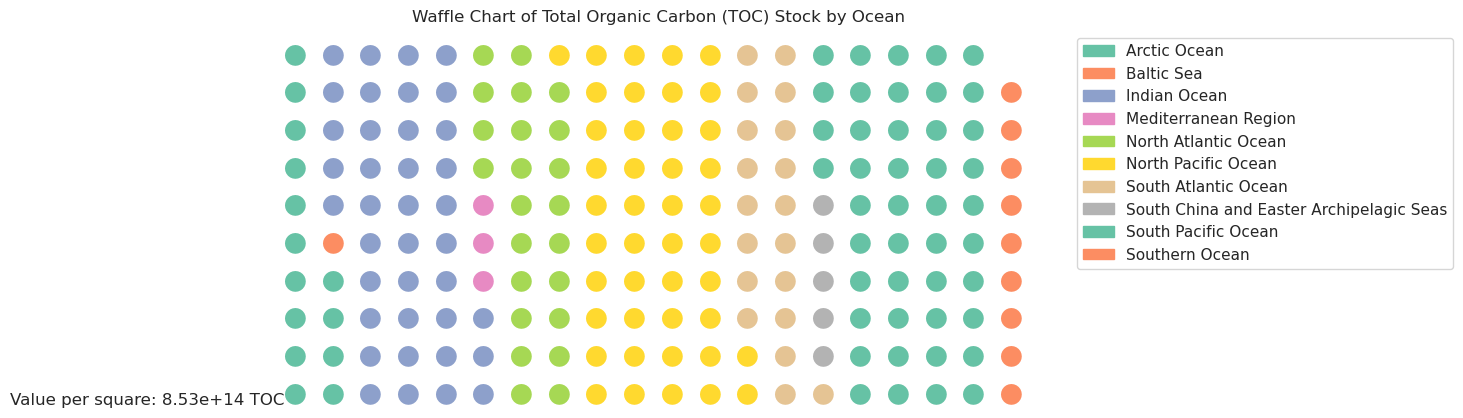

In [91]:
import matplotlib.pyplot as plt
from pywaffle import Waffle

# Define the TOC stock for each ocean
toc_stock = {
    'Arctic Ocean': 1.221704e+16,
    'Baltic Sea': 8.404742e+14,
    'Indian Ocean': 3.234518e+16,
    'Mediterranean Region': 2.762551e+15,
    'North Atlantic Ocean': 1.962081e+16,
    'North Pacific Ocean': 3.633577e+16,
    'South Atlantic Ocean': 1.662456e+16,
    'South China and Easter Archipelagic Seas': 4.211154e+15,
    'South Pacific Ocean': 3.791272e+16,
    'Southern Ocean': 7.828277e+15
}

# Calculate the total TOC stock
total_toc_stock = sum(toc_stock.values())

# Define the number of rows and columns for the waffle chart
rows = 10
columns = 20

# Calculate the total number of squares
total_squares = rows * columns

# Calculate the value represented by each square
value_per_square = total_toc_stock / total_squares

# Create a waffle chart
plt.figure(
    figsize = (15,15),
    FigureClass=Waffle,
    rows=rows,
    columns=columns,
    values=toc_stock,
    legend={'loc': 'upper left', 'bbox_to_anchor': (1.05, 1)},
    icons='circle',  # Change the shape of the squares to circles for better visualization
    icon_size=15,  # Adjust the size of the circles
)
plt.title('Waffle Chart of Total Organic Carbon (TOC) Stock by Ocean')

# Add value per square to the legend
plt.text(0, 0, f'Value per square: {value_per_square:.2e} TOC', ha='right', va='center')

plt.show()


In [64]:
sum_toc_by_polygon


name
Arctic Ocean                                1.221704e+16
Baltic Sea                                  8.404742e+14
Indian Ocean                                3.234518e+16
Mediterranean Region                        2.762551e+15
North Atlantic Ocean                        1.962081e+16
North Pacific Ocean                         3.633577e+16
South Atlantic Ocean                        1.662456e+16
South China and Easter Archipelagic Seas    4.211154e+15
South Pacific Ocean                         3.791272e+16
Southern Ocean                              7.828277e+15
Name: TOC, dtype: float64

In [62]:
ocean_comarge_gdf = gpd.read_file('continental_shelves_separate_ocean.shp')

In [63]:
ocean_comarge_gdf

,name,geometry
0,Southern Ocean,"MULTIPOLYGON (((163.34367 -75.51370, 163.34470..."
1,South Atlantic Ocean,"MULTIPOLYGON (((6.50671 0.00000, 6.50731 -0.00..."
2,South Pacific Ocean,"MULTIPOLYGON (((150.58739 -10.20907, 150.58674..."
3,North Pacific Ocean,"MULTIPOLYGON (((131.09482 0.00000, 131.09482 0..."
4,South China and Easter Archipelagic Seas,"MULTIPOLYGON (((121.95552 21.08333, 122.14722 ..."
5,Indian Ocean,"MULTIPOLYGON (((95.45253 5.68062, 95.45244 5.6..."
6,Mediterranean Region,"MULTIPOLYGON (((-5.40053 35.92186, -5.40092 35..."
7,North Atlantic Ocean,"MULTIPOLYGON (((4.39663 61.00000, 4.39650 60.9..."
8,Arctic Ocean,"MULTIPOLYGON (((2.36587 61.00000, 2.35371 61.0..."


In [64]:
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf = gpd.sjoin(prediction_gdf, ocean_comarge_gdf, op='within')
joined_area_gdf = gpd.sjoin(area_gdf, ocean_comarge_gdf, op='within')

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


In [65]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC in continental shelves of {ocean_name}: {toc_sum/1e15} Gt")

Sum of TOC in continental shelves of Arctic Ocean: 0.6153062448951478 Gt
Sum of TOC in continental shelves of Indian Ocean: 2.28336404672022 Gt
Sum of TOC in continental shelves of Mediterranean Region: 0.48029318262504184 Gt
Sum of TOC in continental shelves of North Atlantic Ocean: 2.2237818521554553 Gt
Sum of TOC in continental shelves of North Pacific Ocean: 1.9078032741934412 Gt
Sum of TOC in continental shelves of South Atlantic Ocean: 1.0647582453743487 Gt
Sum of TOC in continental shelves of South China and Easter Archipelagic Seas: 2.0124568340817413 Gt
Sum of TOC in continental shelves of South Pacific Ocean: 2.3502657554456285 Gt
Sum of TOC in continental shelves of Southern Ocean: 1.3239789005947598 Gt


In [66]:
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf_TOCPercent = gpd.sjoin(tocPercentcCellwise_gdf, ocean_comarge_gdf, op='within')
joined_area_gdf = gpd.sjoin(area_gdf, ocean_comarge_gdf, op='within')

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


In [69]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf_TOCPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC % in continental shelves of {ocean_name}: {toc_sum/1e6} %km^2 (1e6)")

Sum of TOC % in continental shelves of Arctic Ocean: 0.7850986525321668 %km^2 (1e6)
Sum of TOC % in continental shelves of Indian Ocean: 3.1117663550453116 %km^2 (1e6)
Sum of TOC % in continental shelves of Mediterranean Region: 0.7056325911619357 %km^2 (1e6)
Sum of TOC % in continental shelves of North Atlantic Ocean: 3.191950210159994 %km^2 (1e6)
Sum of TOC % in continental shelves of North Pacific Ocean: 2.7482013697122056 %km^2 (1e6)
Sum of TOC % in continental shelves of South Atlantic Ocean: 1.3866351072758838 %km^2 (1e6)
Sum of TOC % in continental shelves of South China and Easter Archipelagic Seas: 2.620138857760239 %km^2 (1e6)
Sum of TOC % in continental shelves of South Pacific Ocean: 3.670352091455039 %km^2 (1e6)
Sum of TOC % in continental shelves of Southern Ocean: 1.3811254352076572 %km^2 (1e6)


In [51]:
# Calculate the sum of TOC in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of continental shelves in {ocean_name}: {area/1e6} million km^2")

Area of continental shelves in Arctic Ocean: 3.10108725 million km^2
Area of continental shelves in Indian Ocean: 6.6899465 million km^2
Area of continental shelves in Mediterranean Region: 1.10668325 million km^2
Area of continental shelves in North Atlantic Ocean: 6.176298 million km^2
Area of continental shelves in North Pacific Ocean: 6.024006 million km^2
Area of continental shelves in South Atlantic Ocean: 3.42089925 million km^2
Area of continental shelves in South China and Easter Archipelagic Seas: 4.10226175 million km^2
Area of continental shelves in South Pacific Ocean: 5.811669 million km^2
Area of continental shelves in Southern Ocean: 4.289367 million km^2


In [43]:
caspian_sea_gdf = gpd.read_file('worldglwd1.shp')

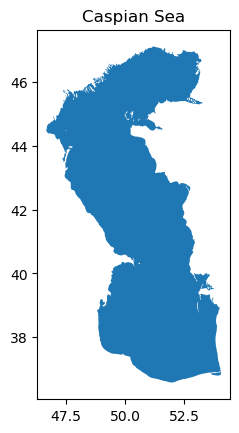

In [44]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Plot the GeoDataFrame
caspian_sea_gdf.plot()
plt.title('Caspian Sea')
plt.show()

In [45]:
caspian_sea_gdf

,glwd_id,type,lake_name,dam_name,poly_src,area_skm,perim_km,long_deg,lat_deg,elev_m,...,mgld_area,lrs_area,lrs_ar_src,lrs_catch,dam_height,dam_year,use_1,use_2,use_3,geometry
0,1,Lake,Caspian Sea,None,ArcWorld,378119.3,6820.3,50.36,41.85,-22.0,...,380000.0,0.0,None,0.0,0.0,0.0,None,None,None,"POLYGON ((51.07708 45.00000, 51.07666 44.99916..."


In [46]:
import geopandas as gpd
import numpy as np

# Reproject caspian_sea_gdf to EPSG:4326
caspian_sea_gdf = caspian_sea_gdf.to_crs(epsg=4326)

# Perform spatial join
joined_gdf = gpd.sjoin(area_gdf, caspian_sea_gdf, how="left", op="within")

# Check the TOC values inside and outside the Caspian Sea
area_inside_caspian = np.nansum(joined_gdf[joined_gdf['lake_name'].notna()]['area'])
area_outside_caspian = np.nansum(joined_gdf[joined_gdf['lake_name'].isna()]['area'])

print(f"Area inside the Caspian Sea: {area_inside_caspian/1e6} million km^2")
print(f"Area outside the Caspian Sea: {area_outside_caspian/1e6} million km^2")

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


Area inside the Caspian Sea: 0.3809408125 million km^2
Area outside the Caspian Sea: 513.075072 million km^2


In [47]:
import geopandas as gpd
import numpy as np

# Reproject caspian_sea_gdf to EPSG:4326
caspian_sea_gdf = caspian_sea_gdf.to_crs(epsg=4326)

# Perform spatial join
joined_gdf = gpd.sjoin(prediction_gdf, caspian_sea_gdf, how="left", op="within")

# Check the TOC values inside and outside the Caspian Sea
toc_inside_caspian = np.nansum(joined_gdf[joined_gdf['lake_name'].notna()]['TOC'])
toc_outside_caspian = np.nansum(joined_gdf[joined_gdf['lake_name'].isna()]['TOC'])

print(f"TOC stock inside the Caspian Sea: {toc_inside_caspian/1e15} Gt")
print(f"TOC stock outside the Caspian Sea: {toc_outside_caspian/1e15} Gt")

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


TOC inside the Caspian Sea: 0.17546878998467874 Gt
TOC outside the Caspian Sea: 172.47642056119722 Gt


In [49]:
import geopandas as gpd
import numpy as np

# Reproject caspian_sea_gdf to EPSG:4326
caspian_sea_gdf = caspian_sea_gdf.to_crs(epsg=4326)

# Perform spatial join
joined_gdf = gpd.sjoin(tocPercentcCellwise_gdf, caspian_sea_gdf, how="left", op="within")

# Check the TOC values inside and outside the Caspian Sea
tocPercent_inside_caspian = np.nansum(joined_gdf[joined_gdf['lake_name'].notna()]['TOCPercent'])
tocPercent_outside_caspian = np.nansum(joined_gdf[joined_gdf['lake_name'].isna()]['TOCPercent'])

print(f"TOC Percent inside the Caspian Sea: {tocPercent_inside_caspian/1e6} % (x10^6)")
print(f"TOC Percent outside the Caspian Sea: {tocPercent_outside_caspian/1e6} % (x10^6)")

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


TOC Percent inside the Caspian Sea: 0.24954229121908905 % (x10^6)
TOC Percent outside the Caspian Sea: 244.61182115014165 % (x10^6)


In [57]:
comarge_gdf = gpd.read_file('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/Comarge/ContinentalMargins.shp')

In [58]:
comarge_gdf

,Uniq_ID,Area,PERIMETRE,SUPERFICIE,geometry
0,0,0.0,0.0,0.0,"MULTIPOLYGON (((-50.95758 -58.19090, -50.95000..."


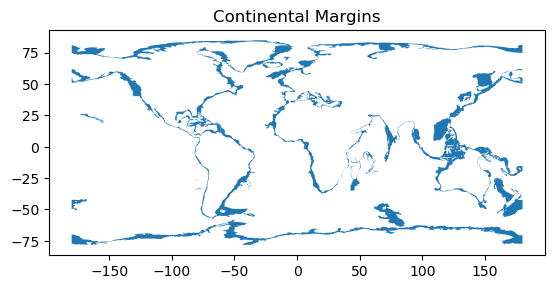

In [59]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Assuming comarge_gdf is your GeoDataFrame
# Replace this with the actual path to your shapefile
comarge_gdf = gpd.read_file('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/Comarge/ContinentalMargins.shp')

# Plot the GeoDataFrame
comarge_gdf.plot()
plt.title('Continental Margins')
plt.show()

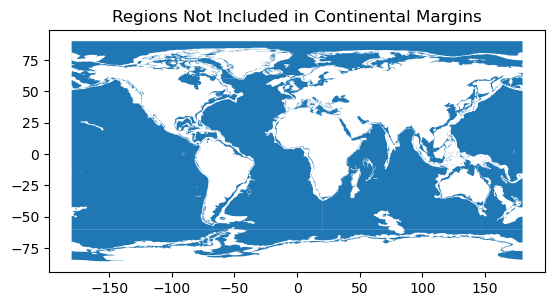

In [60]:
import geopandas as gpd
from shapely.geometry import Polygon

# Assuming world_gdf is a GeoDataFrame representing the entire world
# You may need to replace this with the actual path to your world shapefile
#world_gdf = gpd.read_file('/path/to/world/shapefile.shp')

# Assuming comarge_gdf is your GeoDataFrame representing continental margins
# Assuming world_gdf and comarge_gdf have the same coordinate reference system (CRS)

# Get the difference between the entire world and the continental margins
regions_not_included_gdf = gpd.overlay(ocean_gdf, comarge_gdf, how='difference')

# Plot the regions not included in continental margins
regions_not_included_gdf.plot()
plt.title('Regions Not Included in Continental Margins')
plt.show()


In [61]:
# Intersect the two shapefiles
continental_shelves_df = gpd.overlay(ocean_gdf, comarge_gdf, how="intersection")

In [62]:
import geopandas as gpd

# Filter the results to keep only the relevant columns
continental_shelves_df = continental_shelves_df[["name", "geometry"]]

# Save the new shapefile
continental_shelves_df.to_file("continental_shelves_separate_ocean.shp")

In [63]:
gdf =ocean_gdf

In [64]:
projected_crs = 'EPSG:3395'

# Reproject the geometries to the new CRS
gdf_projected = gdf.to_crs(projected_crs)
# Calculate the area and add a new column
gdf['polygon_area'] = gdf_projected['geometry'].area

In [65]:
gdf

,name,latitude,longitude,min_Y,min_X,max_Y,max_X,area_km2,geometry,polygon_area
0,Southern Ocean,-68.03985,-26.63275,-85.56250,-180.00000,-60.00000,180.00000,6793589,"POLYGON ((180.00000 -60.00000, 180.00000 -84.3...",1.764876e+14
1,South Atlantic Ocean,-33.73758,-18.83411,-60.00000,-69.60084,0.07511,20.00000,42815540,"MULTIPOLYGON (((-50.68008 0.00000, -50.64339 0...",6.638810e+13
2,South Pacific Ocean,-30.09612,-143.06088,-60.00000,130.11129,3.39114,-67.26667,90147400,"MULTIPOLYGON (((-70.93199 -54.75580, -70.92427...",1.292940e+14
3,North Pacific Ocean,26.95013,-169.38334,0.00000,117.51622,66.56286,-76.98544,77124830,"MULTIPOLYGON (((157.14844 57.76842, 157.15257 ...",1.102009e+14
4,South China and Easter Archipelagic Seas,5.62943,115.46548,-10.92259,95.43328,25.56728,134.03155,6822162,"MULTIPOLYGON (((119.28261 25.48829, 119.27451 ...",7.057357e+12
5,Indian Ocean,-27.27272,79.60241,-60.00000,20.00000,31.18586,146.91671,78162363,"MULTIPOLYGON (((56.08700 27.10831, 56.08874 27...",1.094799e+14
6,Mediterranean Region,38.13065,19.70067,30.06809,-6.03255,47.37640,42.35496,2988248,"POLYGON ((32.57319 30.06809, 32.56996 30.06817...",4.854391e+12
7,Baltic Sea,58.78478,19.22115,52.65352,9.36560,67.08059,30.34710,415600,"POLYGON ((27.35543 60.48886, 27.35988 60.48797...",1.557981e+12
8,North Atlantic Ocean,31.77621,-40.24758,-0.93603,-98.05392,68.63872,12.00594,41741693,"MULTIPOLYGON (((-29.42622 68.22895, -23.13435 ...",6.688540e+13
9,Arctic Ocean,79.14792,-3.28568,51.14359,-180.00000,90.00000,180.00000,15571669,"MULTIPOLYGON (((178.29612 69.42748, 178.29961 ...",9.231547e+15


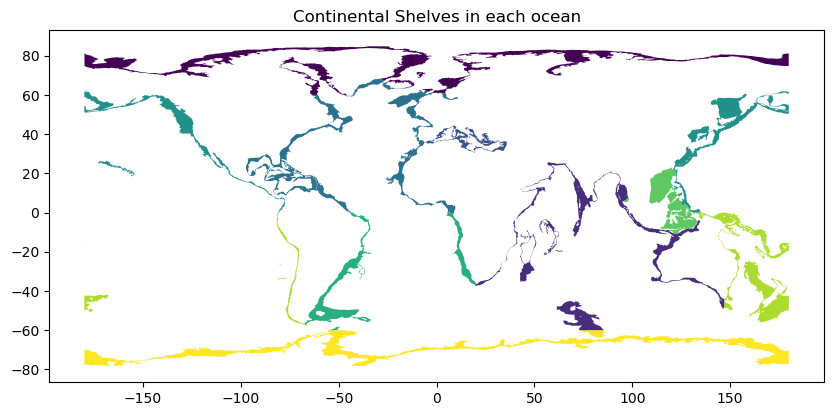

In [66]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Assuming continental_shelves_df is a GeoDataFrame
continental_shelves_gdf = gpd.GeoDataFrame(continental_shelves_df)

# Plot the GeoDataFrame
continental_shelves_gdf.plot(column='name', figsize=(10, 8), cmap='viridis')
plt.title('Continental Shelves in each ocean')
plt.show()

# Save the GeoDataFrame to a shapefile
continental_shelves_gdf.to_file("continental_shelves_separate_ocean.shp")

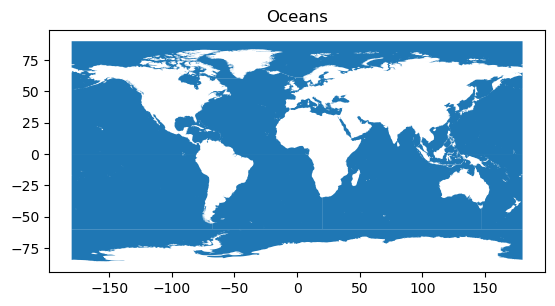

In [67]:
ocean_gdf.plot()
plt.title('Oceans')
plt.show()

In [68]:
np.nansum(prediction_gdf["TOC"]/1e15)

172.651889351182

In [69]:
import geopandas as gpd
import numpy as np

# Assuming prediction_gdf and comarge_gdf are your GeoDataFrames
# Ensure both GeoDataFrames have the same coordinate reference system (CRS)

# Perform spatial join
joined_gdf = gpd.sjoin(prediction_gdf, comarge_gdf, how="left", op="within")

# Check the TOC values inside and outside the continental shelves
toc_inside = np.nansum(joined_gdf[~np.isnan(joined_gdf['Area'])]['TOC'])
toc_outside = np.nansum(joined_gdf[np.isnan(joined_gdf['Area'])]['TOC'])

print(f"Sum of TOC inside continental shelves: {toc_inside/1e15} Gt")
print(f"Sum of TOC outside continental shelves: {toc_outside/1e15} Gt")


/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


Sum of TOC inside continental shelves: 14.273450638289274 Gt
Sum of TOC outside continental shelves: 158.37843871289266 Gt


In [ ]:
import geopandas as gpd

# Assuming comarge_gdf and ocean_gdf are your GeoDataFrames
difference_gdf = gpd.overlay(comarge_gdf, ocean_gdf, how='difference')

# Now, difference_gdf contains the areas covered by comarge_gdf but not by ocean_gdf


In [ ]:
# Create a GeoDataFrame representing the entire region covered by comarge_gdf
full_region_gdf = gpd.GeoDataFrame(geometry=[comarge_gdf.unary_union])

In [ ]:
full_region_gdf.plot()
plt.title('comarge')
plt.show()

In [ ]:
# Create a GeoDataFrame representing the areas covered by comarge_gdf (values = 1)
covered_gdf = gpd.overlay(comarge_gdf, full_region_gdf, how='intersection')


In [ ]:
# Create a NumPy matrix with 1 where covered and 0 where not covered
coverage_matrix = np.zeros_like(full_region_gdf.geometry.iloc[0])

for geom in covered_gdf.geometry:
    coverage_matrix += np.array(full_region_gdf.geometry.iloc[0].contains(geom))

# Now, coverage_matrix contains 1 where comarge_gdf covers and 0 where it doesn't


In [ ]:
from scipy.stats import norm
from scipy.optimize import curve_fit
import numpy as np
from multiprocessing import Pool, Manager

def gaussian_func(x, mu, sigma):
    return norm.pdf(x, mu, sigma)

def fit_gaussian_point(point, failed_fits_count, failed_fit_details):
    i, j, data_point = point

    # Check if data_point contains NaN values, and skip fitting if it does
    if np.isnan(data_point).any():
        #print("nan!")
        return None

    x_values = np.arange(len(data_point))

    try:
        # Fit a Gaussian distribution to the data with an improved initial guess
        mu_init = np.mean(data_point)
        sigma_init = np.std(data_point)
        params, _ = curve_fit(gaussian_func, x_values, data_point, p0=[mu_init, sigma_init])
        return i, j, params
    except Exception as e:
        #print(f"Fit failed for point ({i}, {j}): {str(e)}")
        failed_fits_count.value += 1
        failed_fit_details.append((i, j, str(e)))
        # Write details of failed fits to a file
        with open("failed_fits.txt", "a") as file:
            file.write(f"Failed fit at point ({i}, {j})\n")
        return None

def fit_gaussian_to_predictions(predictions_sum):
    # Assume predictions_sum is your array of shape (100, 6, 4320)
    num_samples, num_points_x, num_points_y = predictions_sum.shape

    # Fitting parameters for each point
    fit_params_gaussian = np.zeros((num_points_x, num_points_y, 2))  # Assuming Gaussian has two parameters (mu, sigma)

    # Count the number of points where the fitting process fails
    manager = Manager()
    failed_fits_count = manager.Value('i', 0)

    # List to store details of failed fits
    failed_fit_details = []

    # Create a list of tuples for each point and its data
    data_points = [(i, j, predictions_sum[:, i, j]) for i in range(num_points_x) for j in range(num_points_y)]

    # Use multiprocessing Pool to parallelize the fitting process
    with Pool() as pool:
        results = pool.starmap(fit_gaussian_point, [(point, failed_fits_count, failed_fit_details) for point in data_points])

    # Process the results
    for result in results:
        if result is not None:
            i, j, params = result
            fit_params_gaussian[i, j] = params

    return fit_params_gaussian, failed_fits_count.value, failed_fit_details

In [ ]:
for i in range(prediction_dist_overlapped.shape[0]):
    prediction_dist_overlapped[i, :, :][land_map] = np.nan


In [ ]:
plt.imshow(np.mean(prediction_dist_overlapped, axis = 0))

In [14]:
failed_fits_all = []
i = 0
fit_params, failed_fits, failed_fit_details = fit_gaussian_to_predictions(prediction_dist_overlapped)
failed_fits_all.append(failed_fits)
print(i)

/gxfs_home/cau/sunms498/.local/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:1010: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',
/gxfs_home/cau/sunms498/.local/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:1010: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',
/gxfs_home/cau/sunms498/.local/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:1010: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',
/gxfs_home/cau/sunms498/.local/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:1010: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',
/gxfs_home/cau/sunms498/.local/lib/python3.11/site-packa

0


In [15]:
failed_fits

37767

In [54]:
failed_fits

41972

In [56]:
(2160*4320)/41972

222.3196416658725

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: ylabel='Count'>

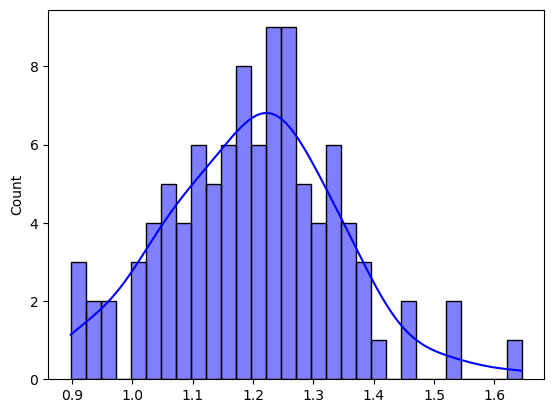

In [62]:
import seaborn as sns
sns.histplot(prediction_dist_overlapped[:,100, 1410], kde=True, bins=30, color='blue', edgecolor='black')

In [49]:
from multiprocessing import Pool

# Function to fit Gaussian to predictions for a specific location
def fit_gaussian_wrapper(args):
    i, j, prediction_dist_overlapped = args
    return fit_gaussian_to_predictions(prediction_dist_overlapped[:, i, j])

# Number of processes (adjust according to your system)
num_processes = 64

# Prepare arguments for parallelization
args_list = [(i, j, prediction_dist_overlapped) for i in range(prediction_dist_overlapped.shape[1])
             for j in range(prediction_dist_overlapped.shape[2])]

# Use multiprocessing.Pool for parallel execution
with Pool(processes=num_processes) as pool:
    results = pool.map(fit_gaussian_wrapper, args_list)

# Extract failed fits from the results
failed_fits_all = [result[1] for result in results]

# Print progress
for i in range(prediction_dist_overlapped.shape[1]):
    print(i)

Process ForkPoolWorker-25:
Process ForkPoolWorker-42:
Process ForkPoolWorker-41:
Process ForkPoolWorker-3:
Process ForkPoolWorker-44:
Process ForkPoolWorker-61:
Process ForkPoolWorker-18:
Process ForkPoolWorker-46:
Process ForkPoolWorker-39:
Process ForkPoolWorker-53:
Process ForkPoolWorker-2:
Process ForkPoolWorker-9:
Process ForkPoolWorker-31:
Process ForkPoolWorker-49:
Process ForkPoolWorker-54:
Process ForkPoolWorker-14:
Process ForkPoolWorker-50:
Process ForkPoolWorker-17:
Process ForkPoolWorker-16:
Process ForkPoolWorker-36:
Process ForkPoolWorker-33:
Process ForkPoolWorker-7:
Process ForkPoolWorker-27:
Process ForkPoolWorker-8:
Process ForkPoolWorker-28:
Process ForkPoolWorker-20:
Process ForkPoolWorker-22:
Process ForkPoolWorker-35:
Process ForkPoolWorker-57:
Process ForkPoolWorker-4:
Process ForkPoolWorker-59:
Process ForkPoolWorker-21:
Process ForkPoolWorker-11:
Process ForkPoolWorker-37:
Process ForkPoolWorker-38:
Process ForkPoolWorker-47:
Process ForkPoolWorker-62:
Process

UnpicklingError: invalid load key, '?'.

In [ ]:
"""

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Replace `mar_naveen_nonan` and `north_sea_bounds` with your data and region bounds
# mar_naveen_nonan = ...

# Define the boundaries for the North Sea region (modify as needed)
north_sea_bounds = [-10, 10, 50, 62]

# Create a figure
plt.figure(figsize=(10, 10), dpi=100)

# Plot the data using imshow
plt.imshow(mar_naveen_nonan, norm=LogNorm(vmin=1e-5, vmax=5), cmap="cubehelix", extent=[-180, 180, -90, 90])

# Set the extent to focus on the North Sea region
plt.xlim(north_sea_bounds[0], north_sea_bounds[1])
plt.ylim(north_sea_bounds[2], north_sea_bounds[3])

# Add labels and title (uncomment if needed)
plt.xlabel('Longitude', fontsize=20)
plt.ylabel('Latitude', fontsize=20)
plt.title('Mass Accumulation Rate in the North Sea', fontsize=20)

# Add a color bar with manually calculated aspect
cax = plt.colorbar(label='Mass Accumulation Rate', pad=0.015, shrink=0.46)
cax.ax.tick_params(labelsize=20)
cax.set_label('Mass Accumulation Rate (g/cm²/yr)', fontsize=20)

# Manually calculate the aspect ratio to match the plot size
aspect = 10  # Adjust this value as needed to match your plot size
cax.ax.set_aspect(aspect)

# Increase font size for ticks
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)

plt.tight_layout()

# Show the plot
plt.show()


# Load data from the 6 npy files
mar_constraint01 = np.load('/home/sunms498/Downloads/klaus_meeting/mar_constraint01.npy')
mar_constraint02 = np.load('/home/sunms498/Downloads/klaus_meeting/mar_constraint02.npy')
mar_constraint03 = np.load('/home/sunms498/Downloads/klaus_meeting/mar_constraint03.npy')
mar_constraint04 = np.load('/home/sunms498/Downloads/klaus_meeting/mar_constraint04.npy')
mar_noconstraint = np.load('/home/sunms498/Downloads/klaus_meeting/mar_noconstraint.npy')
mar_constraint0 = np.load('/home/sunms498/Downloads/klaus_meeting/mar_constraint0.npy')

# Combine the data into a single array (modify the order as needed)
mar_naveen_nonan = np.stack([mar_constraint0,mar_constraint01, mar_constraint02, mar_constraint03, mar_constraint04, mar_noconstraint])


# Define the boundaries for the North Sea region (modify as needed)
north_sea_bounds = [-10, 10, 50, 62]

# Create a 3x2 grid of plots with shared x and y axes
fig, axs = plt.subplots(3, 2, figsize=(20, 20), dpi=100, sharex=True, sharey=True)
constraint_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
# Plot the data using imshow for each subplot
for i, ax in enumerate(axs.flatten()):
    im = ax.imshow(mar_naveen_nonan[i], norm=LogNorm(vmin=1e-5, vmax=5), cmap="cubehelix", extent=[-180, 180, -90, 90])
    ax.set_xlim(north_sea_bounds[0], north_sea_bounds[1])
    ax.set_ylim(north_sea_bounds[2], north_sea_bounds[3])
    # Annotate the subplot with the constraint value
    constraint_value = constraint_values[i]  # Modify as needed
    ax.annotate(f'$\lambda$: {constraint_value}', xy=(0.85, 0), xycoords='axes fraction',
                fontsize=20, ha='right', va='bottom')
# Manually set labels for the axes if needed
axs[2, 0].set_xlabel('Longitude', fontsize=20, labelpad=10)  
axs[2, 0].xaxis.set_label_coords(1.05, -0.1)  
axs[1, 0].set_ylabel('Latitude', fontsize=20)

# Add a color bar centered on the last subplot
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # Adjust position and size to center the color bar
cbar = plt.colorbar(im, cax=cax, label='Mass Accumulation Rate')
cbar.ax.tick_params(labelsize=20)
cbar.set_label('Mass Accumulation Rate (g/cm²/yr)', fontsize=20)

# Increase font size for ticks on all subplots
for ax in axs.flatten():
    ax.tick_params(labelsize=20)

# Remove titles
for ax in axs.flatten():
    ax.set_title('')

# Remove white spaces between the plots
plt.subplots_adjust(wspace=0, hspace=0)

axs[2,0].set_xticks(axs[2,0].get_xticks()[:-1])

# Remove the leftmost x-tick in the left column

axs[0,1].set_xticks(axs[0,1].get_xticks()[1:])
"""
# Show the plot
plt.show()
# Save the plot with high resolution for publication
#plt.savefig('published_plot.png', dpi = 25, bbox_inches='tight')
"""
plt.show()
plt.figure(figsize=([20,10]),dpi = 25)
plt.imshow(area)
plt.title("Area of grid cell")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
plt.axis("off")
plt.colorbar(label='Area(km2) ')
#plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
"""


#mar_restreppo = 10**dataset_numpy_2021

# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(mar_restreppo,norm=LogNorm(vmin=1e-5, vmax=5),cmap="cubehelix")
# plt.title("Global mass accumulation rate from R21 paper")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$]')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")

print(int(np.sum(area * mar_naveen_nonan)))

# prediction_map_shallow = np.load("/home/sunms498/work/toc-neural-nets/Sed_regresion_shallow_RestrepoFeats_AllVS0.2_noNaN.npy")
# prediction_map_shallow_flipped= np.rot90(np.rot90(np.fliplr(prediction_map_shallow)))
# prediction_map_shallow_flipped[land_map]=np.nan


# mar_naveen_shallow_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_shallow_flipped/1e3)
# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(mar_naveen_shallow_nonan,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction(trained with only sed rates from shallow regions(>-200m)) from neural network model(ds=2.6)(noNan values)")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log

# prediction_map_deep = np.load("/home/sunms498/work/toc-neural-nets/Sed_regresion_deep_RestrepoFeats_AllVS0.2_noNaN.npy")
# prediction_map_deep_flipped= np.rot90(np.rot90(np.fliplr(prediction_map_deep)))
# prediction_map_deep_flipped[land_map]=np.nan


# mar_naveen_deep_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_deep_flipped/1e3)
# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(mar_naveen_deep_nonan,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction(trained with only sed rates from deep regions(<-200m)) from neural network model(ds=2.6)(noNan values)")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log

# mar_combined_model = np.zeros([prediction_map_deep_flipped.shape[0], prediction_map_deep_flipped.shape[1]])
# mask_shallow = np.load("mask_shallow.npy")
# mask_shallow = np.rot90(np.rot90(np.fliplr(mask_shallow)))
# for i in range(mask_shallow.shape[0]):
#     for j in range(mask_shallow.shape[1]):
#         if mask_shallow[i][j]==255:
#             mar_combined_model[i][j]=mar_naveen_shallow_nonan[i][j]
#         else:
#             mar_combined_model[i][j]=mar_naveen_deep_nonan[i][j]

# x_labels=[-180, -90, 0,  90, 180 ]#np.linspace(-180,180,4320)
# fig, ax = plt.subplots(figsize=([20,10]),dpi = 25)
# ax.set_xticklabels(x_labels)
# plt.imshow(mar_combined_model,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction, combining deep and shallow sed rates from neural network model(ds=2.6)(noNan values)")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')

###############################################################################

# prediction_map_nolimit = np.load("/home/sunms498/Data/prediction_map_noNAN_nolimit_1000x6.npy")
# prediction_map_nolimit = 10**prediction_map_nolimit -1
# prediction_map_nolimit_flipped= np.rot90(np.rot90(np.fliplr(prediction_map_nolimit)))
# prediction_map_nolimit_flipped[land_map]=np.nan




# mar_naveen_nolimit_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_nolimit_flipped/1e3)
# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(mar_naveen_nolimit_nonan,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction trained with all the data: regression")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log
            

# variance_map_nolimit = np.load("/home/sunms498/Data/variance_map_noNAN_nolimit_1000x6.npy")
# variance_map_nolimit_flipped= np.rot90(np.rot90(np.fliplr(variance_map_nolimit)))
# variance_map_nolimit_flipped[land_map]=np.nan


#

# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(variance_map_nolimit_flipped,norm=LogNorm(vmin=1e-3, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate variance trained with all the data: regression")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log

###############################################################################
# prediction_map_nolimit_bayes = np.load("/home/sunms498/Data/prediction_map_noNAN_nolimit_bayes.npy")
# prediction_map_nolimit_bayes = 10**prediction_map_nolimit_bayes -1
# prediction_map_nolimit_bayes_flipped= np.rot90(np.rot90(np.fliplr(prediction_map_nolimit_bayes)))
# #prediction_map_nolimit_bayes_flipped[land_map]=np.nan



# mar_naveen_nolimit_nonan_bayes = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_nolimit_bayes_flipped/1e3)
# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(mar_naveen_nolimit_nonan_bayes,norm=LogNorm(vmin=1e-3, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction trained with all the data: bayes")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log
            

# variance_map_nolimit_bayes = np.load("/home/sunms498/Data/variance_map_noNAN_nolimit_bayes.npy")
# variance_map_nolimit_bayes_flipped= np.rot90(np.rot90(np.fliplr(variance_map_nolimit_bayes)))
# variance_map_nolimit_bayes_flipped[land_map]=np.nan




# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(variance_map_nolimit_bayes_flipped,cmap="turbo")
# plt.title("Mass accumulation rate variance trained with all the data: bayes")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log
###############################################################################

# prediction_map_nolimit_softmax = np.load("/home/sunms498/Data/prediction_map_noNAN_nolimit_softmax.npy")
# #prediction_map_nolimit_softmax = 10**prediction_map_nolimit_softmax -1
# prediction_map_nolimit_softmax_flipped= np.rot90(np.rot90(np.fliplr(prediction_map_nolimit_softmax)))
# #prediction_map_nolimit_softmax_flipped[land_map]=np.nan



# mar_naveen_nolimit_nonan_softmax = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_nolimit_softmax_flipped/1e3)
# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(mar_naveen_nolimit_nonan_softmax,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction trained with all the data: softmax")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log
            

# variance_map_nolimit_softmax = np.load("/home/sunms498/Data/variance_map_noNAN_nolimit_softmax.npy")
# variance_map_nolimit_softmax_flipped= np.rot90(np.rot90(np.fliplr(variance_map_nolimit_softmax)))
# variance_map_nolimit_softmax_flipped[land_map]=np.nan




# plt.figure(figsize=([20,10]),dpi = 25)
# plt.imshow(variance_map_nolimit_softmax_flipped,cmap="turbo")
# plt.title("Mass accumulation rate variance trained with all the data: softmax")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log

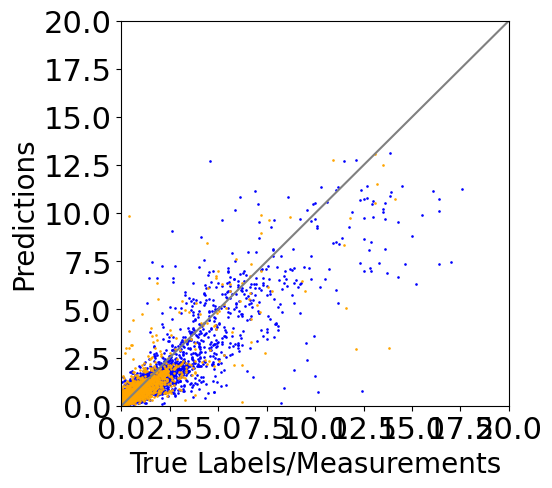

train predictions
Pearson Correlation Coefficient: 0.9087968614908064
R-squared Score: 0.8072371869363262
test predictions
Pearson Correlation Coefficient: 0.8534924113935718
R-squared Score: 0.7253968343271273


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from scipy.stats import pearsonr
import pandas as pd

# Load data from the files
all_predictions_CS = np.load('../../notebooks/TOC/all_predictions_NN_CS.npy')
all_predictions_DO = np.load('../../notebooks/TOC/all_predictions_NN_DO.npy')
all_labels_CS = np.load('../../notebooks/TOC/all_labels_NN_CS.npy')
all_labels_DO = np.load('../../notebooks/TOC/all_labels_NN_DO.npy')

test_predictions_CS = np.load('../../notebooks/TOC/test_predictions_NN_CS.npy')
test_predictions_DO = np.load('../../notebooks/TOC/test_predictions_NN_DO.npy')
test_labels_CS = np.load('../../notebooks/TOC/test_labels_NN_CS.npy')
test_labels_DO = np.load('../../notebooks/TOC/test_labels_NN_DO.npy')

"""
# Creating dataframes
df_all_CS = pd.DataFrame({
    'Labels': all_labels_CS,
    'Predictions': all_predictions_CS
})

df_all_DO = pd.DataFrame({
    'Labels': all_labels_DO,
    'Predictions': all_predictions_DO
})

df_test_DO = pd.DataFrame({
    'Labels': test_labels_DO,
    'Predictions': test_predictions_DO
})

df_test_CS = pd.DataFrame({
    'Labels': test_labels_CS,
    'Predictions': test_predictions_CS
})


# Merge dataframes on 'Labels'
merged_all_CS = pd.merge(df_all_CS, df_test_CS, on='Labels', how='left', suffixes=('_all', '_test'))

# Filter out rows that are present in both dataframes
df_train_CS = merged_all_CS[merged_all_CS['Predictions_test'].isnull()].drop(columns=['Predictions_test'])

# Repeat the same process for the 'DO' dataframes
merged_all_DO = pd.merge(df_all_DO, df_test_DO, on='Labels', how='left', suffixes=('_all', '_test'))
df_train_DO = merged_all_DO[merged_all_DO['Predictions_test'].isnull()].drop(columns=['Predictions_test'])


"""

# Concatenate the predictions and labels
all_predictions = np.concatenate((all_predictions_CS, all_predictions_DO))
all_labels = np.concatenate((all_labels_CS, all_labels_DO))



test_predictions = np.concatenate((test_predictions_CS, test_predictions_DO))
test_labels = np.concatenate((test_labels_CS, test_labels_DO))

# Concatenate the train predictions and labels
train_predictions = np.concatenate((all_predictions_CS[~np.isin(all_labels_CS, test_labels_CS)],
                                    all_predictions_DO[~np.isin(all_labels_DO, test_labels_DO)]))

train_labels = np.concatenate((all_labels_CS[~np.isin(all_labels_CS, test_labels_CS)],
                               all_labels_DO[~np.isin(all_labels_DO, test_labels_DO)]))


line = np.linspace(0,20,100)
plt.figure(figsize=([5, 5]), dpi = 100)
# Plotting
plt.scatter(train_labels, train_predictions, color = "blue", s = 0.8, label = "All labels")
plt.scatter(test_labels, test_predictions, color = "orange", s = 0.8,label = "Test labels")
plt.plot(line, line, color = "grey")
#plt.title('Scatter Plot of Predictions vs Labels(KNN)')
plt.xlabel('True Labels/Measurements', fontsize=20)
plt.ylabel('Predictions', fontsize=20)
plt.xlim(0,20)
plt.ylim(0,20)
plt.xticks(fontsize=22)
plt.yticks(fontsize=22)
#plt.legend(fontsize=20)
plt.show()
print("train predictions")

# Calculate Pearson correlation coefficient
pearson_corr = np.corrcoef(train_labels, train_predictions)[0, 1]
print(f'Pearson Correlation Coefficient: {pearson_corr}')

# Calculate R-squared score
r2 = r2_score(train_labels, train_predictions)
print(f'R-squared Score: {r2}')


print("test predictions")

# Calculate Pearson correlation coefficient
pearson_corr = np.corrcoef(test_labels, test_predictions)[0, 1]
print(f'Pearson Correlation Coefficient: {pearson_corr}')

# Calculate R-squared score
r2 = r2_score(test_labels, test_predictions)
print(f'R-squared Score: {r2}')

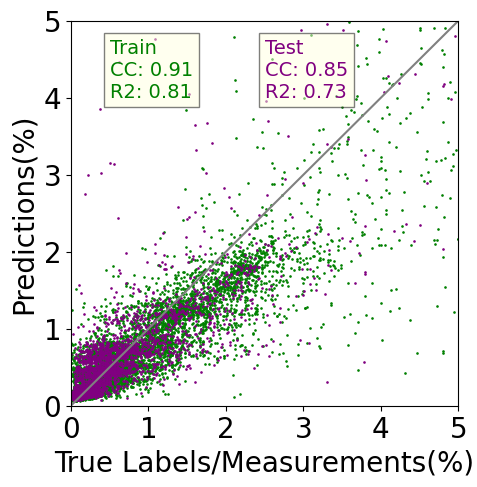

In [7]:
line = np.linspace(0, 20, 100)
plt.figure(figsize=(5, 5), dpi=100)
# Plotting
plt.scatter(train_labels, train_predictions, color="green", s=0.8, label="All labels")
plt.scatter(test_labels, test_predictions, color="purple", s=0.8, label="Test labels")
plt.plot(line, line, color="grey")
plt.xlabel('True Labels/Measurements(%)', fontsize=20)
plt.ylabel('Predictions(%)', fontsize=20)
plt.axis('equal')
plt.axis('tight')  # Adjust plot limits tightly
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)

# Calculate Pearson correlation coefficient and R-squared score for train predictions
pearson_corr_train = np.corrcoef(train_labels, train_predictions)[0, 1]
r2_train = r2_score(train_labels, train_predictions)


# Calculate Pearson correlation coefficient and R-squared score for test predictions
pearson_corr_test = np.corrcoef(test_labels, test_predictions)[0, 1]
r2_test = r2_score(test_labels, test_predictions)


# Adding text inside the plot in a box with different colors
text_train = f'Train \nCC: {pearson_corr_train:.2f}\nR2: {r2_train:.2f}'
text_test = f'Test \nCC: {pearson_corr_test:.2f}\nR2: {r2_test:.2f}'
plt.text(0.5, 4, text_train, fontsize=14, color='green', bbox=dict(facecolor='lightyellow', alpha=0.5))
plt.text(2.5, 4, text_test, fontsize=14, color='purple', bbox=dict(facecolor='lightyellow', alpha=0.5))

plt.show()


In [12]:
# Concatenate the train predictions and labels
train_predictions = np.concatenate((all_predictions_CS[~np.isin(all_labels_CS, test_labels_CS)],
                                    all_predictions_DO[~np.isin(all_labels_DO, test_labels_DO)]))

train_labels = np.concatenate((all_labels_CS[~np.isin(all_labels_CS, test_labels_CS)],
                               all_labels_DO[~np.isin(all_labels_DO, test_labels_DO)]))


In [7]:
train_predictions.shape

(13223,)

In [3]:
all_labels_CS = np.load('../../notebooks/TOC/all_labels_KNN_CS.npy')
all_labels_DO = np.load('../../notebooks/TOC/all_labels_KNN_DO.npy')
all_predictions_CS = np.load('../../notebooks/TOC/all_predictions_KNN_CS.npy')
all_predictions_DO = np.load('../../notebooks/TOC/all_predictions_KNN_DO.npy')
lats_DO = np.load('../../notebooks/TOC/lats_DO.npy')
lats_CS = np.load('../../notebooks/TOC/lats_CS.npy')
lons_DO = np.load('../../notebooks/TOC/lons_DO.npy')
lons_CS = np.load('../../notebooks/TOC/lons_CS.npy')
all_labels = np.concatenate((all_labels_CS, all_labels_DO))
all_targets = np.concatenate((all_predictions_CS, all_predictions_DO))
lats = np.concatenate((lats_CS, lats_DO))
lons = np.concatenate((lons_CS, lons_DO))


DataFrame df3:
       Difference   Latitude  Longitude
0        0.713125  36.875000 -74.613300
1        0.712727 -16.021650 -38.620000
2        1.541176 -16.340000 -38.470000
3        3.547826 -18.481650 -38.689150
4        2.785714 -18.960000 -39.110000
...           ...        ...        ...
22187    0.011305  60.960525   4.036843
22188    0.011566  60.960525   4.126317
22189    0.019699  60.960525   4.215787
22190    0.012293  60.960525   4.290350
22191    0.868698  60.960525   4.454387

[22192 rows x 3 columns]


/tmp/ipykernel_3856926/4069026755.py:38: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


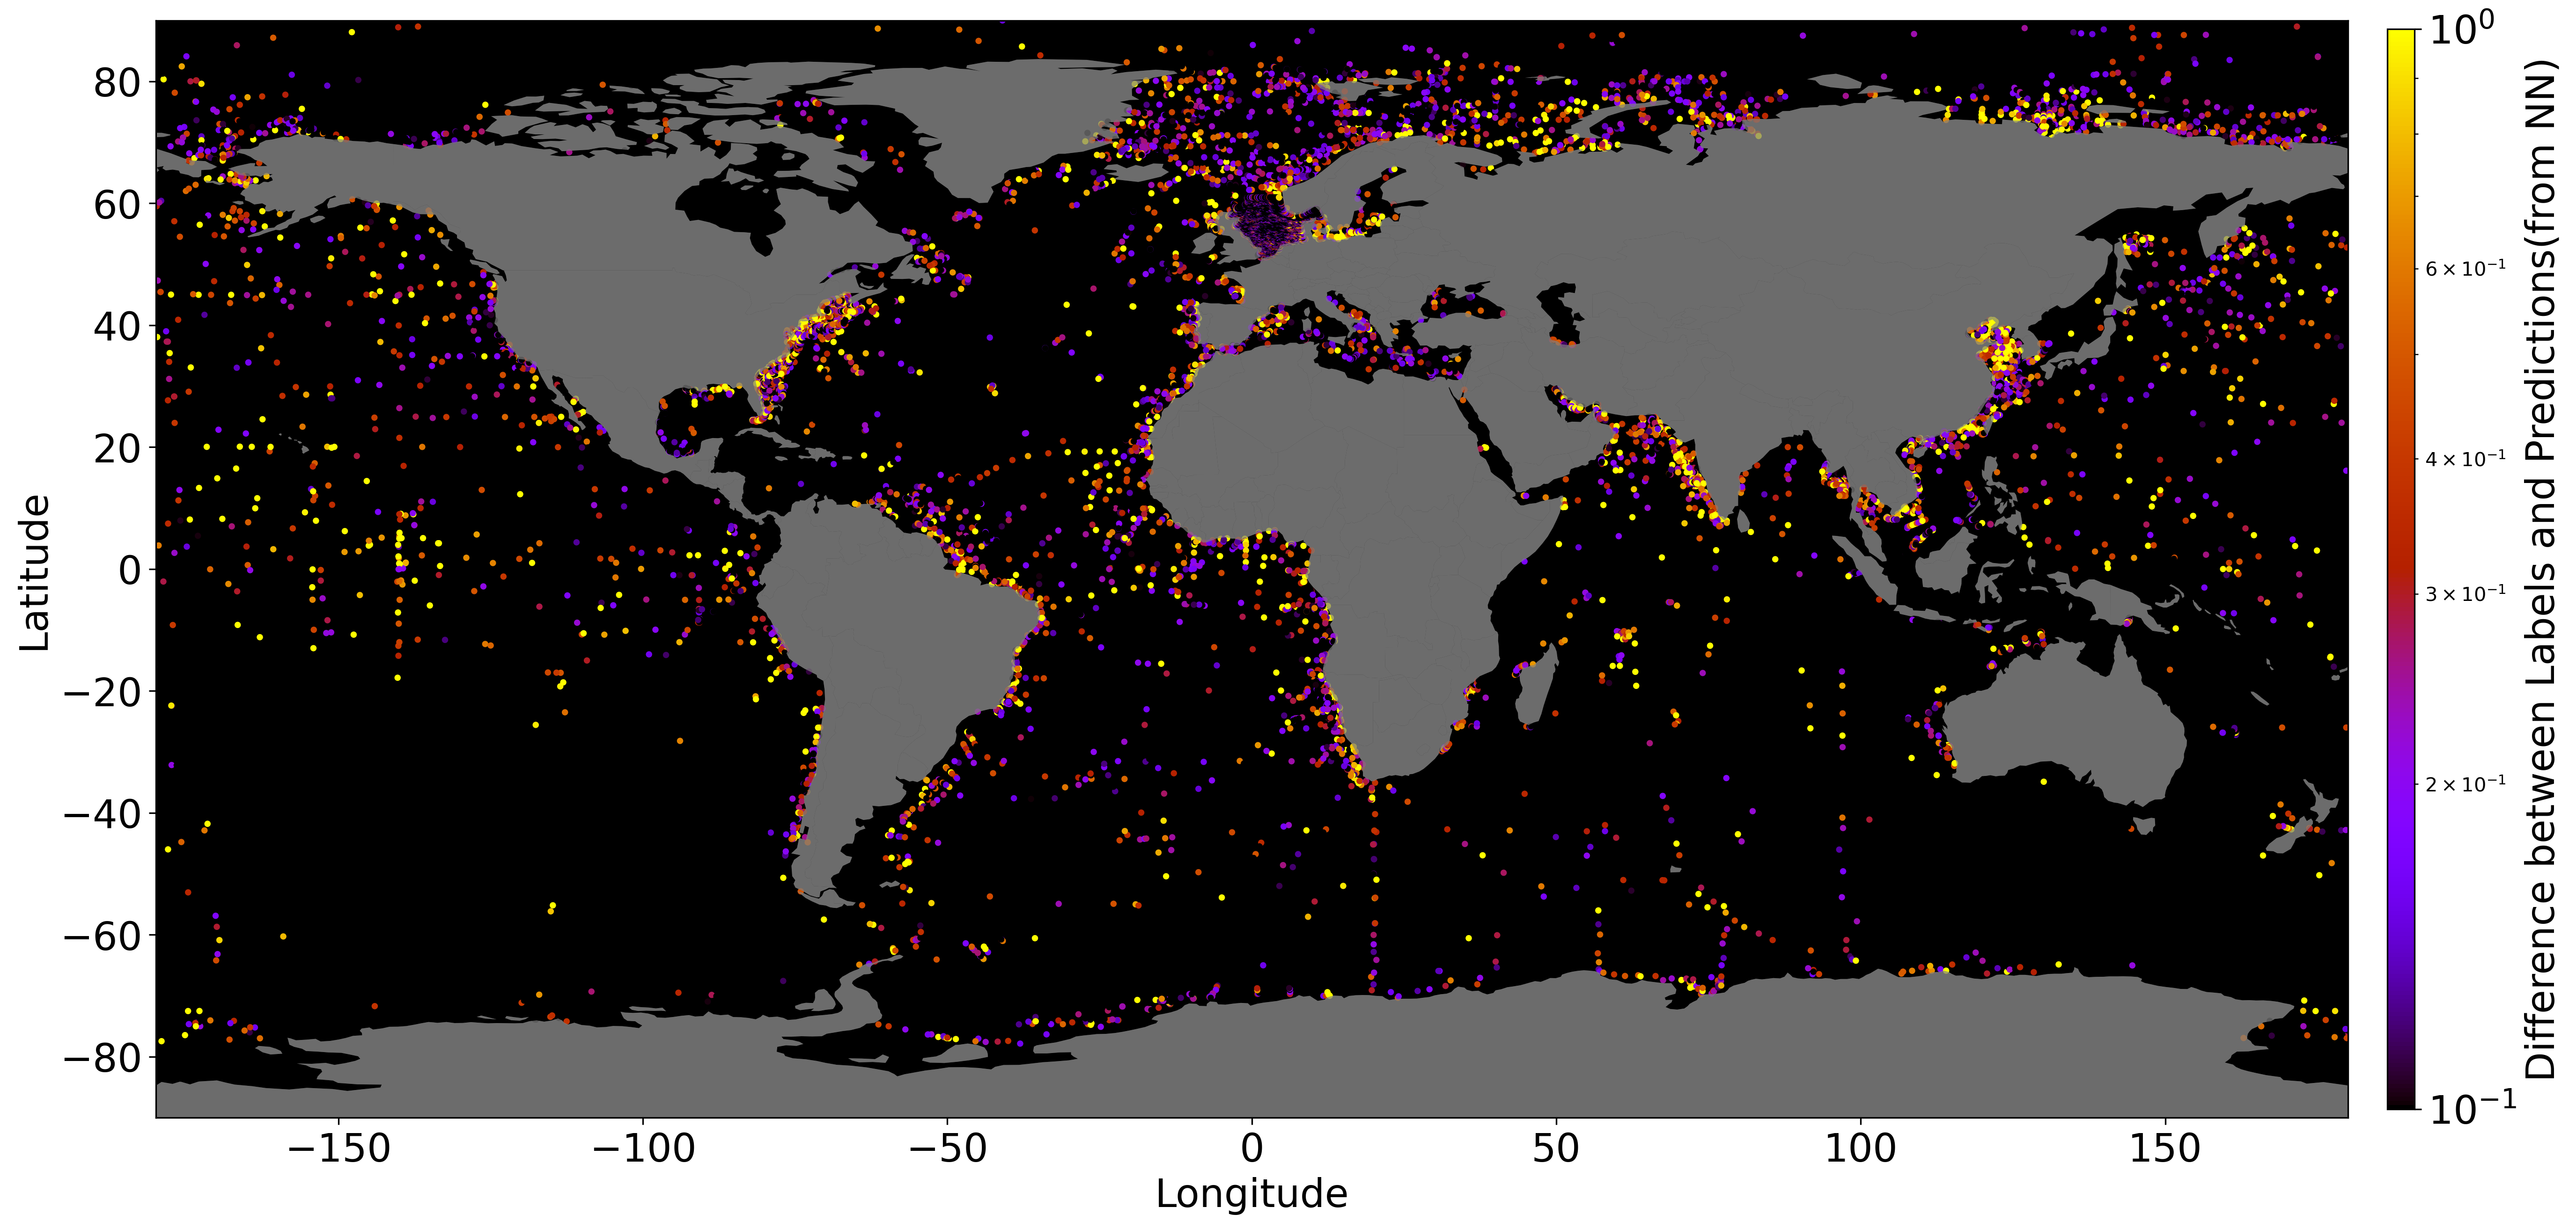

In [13]:
import pandas as pd
import numpy as np

# Assuming 'test_labels', 'test_targets', 'lats', and 'lons' are your numpy arrays
# Replace them with your actual data

# Create DataFrame df1 with test labels, lats, and lons
df1_data = {'Test_Labels': all_labels, 'Latitude': lats, 'Longitude': lons}
df1 = pd.DataFrame(df1_data)

# Create DataFrame df2 with test targets, lats, and lons
df2_data = {'Test_Targets': all_targets, 'Latitude': lats, 'Longitude': lons}
df2 = pd.DataFrame(df2_data)

# Create DataFrame df3 by taking the difference between df1 and df2
df3_data = {'Difference': abs(df1['Test_Labels'] - df2['Test_Targets'])/df1['Test_Labels'], 'Latitude': df1['Latitude'], 'Longitude': df1['Longitude']}
df3 = pd.DataFrame(df3_data)

# Display the DataFrame df3
print("\nDataFrame df3:")
print(df3)

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from matplotlib.colors import LogNorm
# Assuming df3 is your DataFrame
# Replace df3 with your actual DataFrame

# Create a GeoDataFrame from df3
geometry = [Point(xy) for xy in zip(df3['Longitude'], df3['Latitude'])]
gdf = gpd.GeoDataFrame(df3, geometry=geometry)

# Plotting
fig, ax = plt.subplots(figsize=(20, 10), dpi = 25)  # Adjust the figsize as needed

# Plotting the world map
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
world.plot(ax=ax, alpha=0.5, color='grey')
ax.set_facecolor('black')  # Light blue color
# Scatter plot for differences with colors representing the differences
# Scatter plot for differences with log-scaled colors in the scatter plot
scatter = ax.scatter(
    gdf['Longitude'],
    gdf['Latitude'],
    c=abs(gdf['Difference']),
    cmap='gnuplot',
    #vmin = -5, vmax = 5,
    norm=LogNorm(vmin = 1e-1, vmax = 1e0),  # Applying log scale to the scatter plot
    s=5
    
)

# Add a colorbar with the original differences in log scale
cbar = plt.colorbar(scatter, aspect=40, pad=0.015, shrink=0.8)
#cbar = plt.colorbar(label = 'Difference (Test_Labels - Test_Targets)', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label(label = 'Difference between Labels and Predictions(from NN)', fontsize=20)

world.plot(ax=ax, alpha=0.7, color='grey')


# Set font size for all elements
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
#plt.title("TOC data points", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.legend(fontsize=20)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
#plt.title("TOC data points")
plt.tight_layout()
plt.show()

